# Applying supervised learning to predict student dropout

## **Disclaimer**

The work outlined here has been originally submitted as a project for the CAM PACE DS P1 26 Programme.

The business scenario is based on a real-life problem and is subject to an NDA. Therefore, any data, output, or feature name that could potentially implicate the company involved has been redacted to preserve confidentiality.



## **Business Context**

In this project, we will examine student data and use supervised learning techniques to predict whether a student will drop out. In the education sector, retaining students is vital for the institution's financial stability and for students’ academic success and personal development. A high dropout rate can lead to significant revenue loss, diminished institutional reputation, and lower overall student satisfaction.

We will work with the data in three distinct stages:

1.  Applicant and course information
2.  Student and engagement data
3.  Academic performance data

For the analysis, we will:
- explore the data sets, taking a phased approach
- preprocess the data and conduct feature engineering
- predict the dropout rate using XGBoost, and a neural network-based model.


## Collectively import all the libraries required for the project

In [ ]:
# Import the relevant libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from google.colab import files
from datetime import date
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
import keras
from keras.models import Sequential
from keras import layers, Input
from keras.layers import Dense, Dropout
from keras.optimizers import Adam, RMSprop
from keras.regularizers import l2
from keras.callbacks import EarlyStopping
from keras.metrics import AUC



In [ ]:
!pip install -q -U keras-tuner
import keras_tuner as kt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 818.8 kB/s eta 0:00:00


In [ ]:
pip install -q "scikit-optimize"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 1.4 MB/s eta 0:00:00


In [ ]:
from skopt import BayesSearchCV
from skopt.space import Real, Integer
from scipy.stats import uniform

In [ ]:
# Ensure reproducability
# from keras import initializers
keras.utils.set_random_seed(812)
np.random.seed(42)


# Stage 1 data

In [ ]:
# File URL
file_url = "Redacted_1"

**Stage 1: Pre-processing instructions**
- Remove any columns not useful in the analysis.
- Remove columns with categorical features with high cardinality (use >200 unique values, as a guideline for this data set).
- Remove columns with > 50% data missing.
- Perform ordinal encoding for ordinal data.
- Perform one-hot encoding for all other categorical data.

## Pre-Processing the Stage 1 Dataset

### 1.1 A View and pre-assess the dataset for duplicates and missing values.

In [ ]:
# Load the dataset
data_stage1 = pd.read_csv(file_url)
data_stage1.sample(5)

In [ ]:
# Check for null values
print(data_stage1.shape)
data_stage1.info()

The non-null count performed for each column suggests missing values are present for most features; whereas the data type indicates a high percentage of categorical features.

In [ ]:
# Check for duplicated rows
data_stage1[data_stage1.duplicated()]

In [ ]:
# Check if there are duplicates within LearnerCode
dup_idx=data_stage1["RedactedFeature"].index.duplicated()
print(dup_idx.sum())

0


The "RedactedFeature" which acts as a unique identifier for the students does not contain any duplicates which means the dataset is devoid of repeated student entries.

In [ ]:
# Make a copy of the raw dataset
data_stage1_raw=data_stage1.copy()

### 1.1 B Convert target variable stored under feature 'CompletedCourse' to binary and rename it to 'DropOut'

Use the following initialisation:
* CompletedCourse_Yes = DropOut_No : '0'
* CompletedCourse_No = DropOut_Yes: '1'

In [ ]:
# Rename CompletedCourse to DropOut
data_stage1.rename(columns={'CompletedCourse': 'DropOut'}, inplace=True)
# data_stage1.columns.tolist()

In [ ]:
# Map Yes and Nos to '0' and '1's
data_stage1['DropOut']=data_stage1['DropOut'].map({'Yes': float(0), 'No': float(1)})


### 1.1 C Convert "DateofBirth" feature to "Age"

In [ ]:
# Function to convert student birth date to age
def convert_to_age(data_column):
  today = date.today()
  DOB = pd.to_datetime(data_column, format="%d/%m/%Y")
  age = today.year - DOB.year - ((today.month, today.day) < (DOB.month, DOB.day))
  return float(age)

In [ ]:
# Perform conversion
data_stage1['Age'] = data_stage1['DateofBirth'].apply(convert_to_age)

In [ ]:
# data_stage1.info()

In [ ]:
# View dataset
print(data_stage1.shape)
data_stage1.sample(5)

**To aid with version control:** From this point onwards, the dataset will be stored under a new dataframe marked by "_number" with the number indicating the version number following each (data processing) edit.

### 1.1 D Identify columns/features not necessary in the analysis:

* The target variable is the student dropout which is now governed by the DropOut column. Therefore, features that are not likely to have an effect on the student dropout need to be identified.

* For instance features used as student identifiers such as the student number or name will have no effect on a student's likelihood of dropout.

* In the current case, the "RedactedFeature" is the unique student identifier and thus, can be dropped.

* The two features relating to how the student has heard about the course programme and consequently has made the booking, are not likely to have an effect on the student dropout either.

* However, these could tell whether students referred by an agent have a higher or a lower dropout rate compared to other mechanisms. Thus, further exploration could prove useful.


In [ ]:
# Function to remove features deemed unnecessary
def remove_unnecessary(dataframe, features_to_remove):
    return dataframe.drop(features_to_remove, axis=1)

In [ ]:
# Remove the feature acting as the unique identifier
data_stage1_1=remove_unnecessary(data_stage1, ['RedactedFeature'])
print(data_stage1_1.shape)

(25059, 16)


### 1.1 E Remove columns with categorical features with high cardinality (use >200 unique values, as a guideline for this data set).

In [ ]:
# Function to remove categorical features with high cardinality
def remove_high_cardinality(dataframe,num_type):
  cat_cols=dataframe.select_dtypes(exclude=num_type).columns.tolist()
  features_to_remove=[]
  for col in cat_cols:
    cardinality=len(dataframe[col].unique())
    print(f"{col}: {cardinality} unique values")
    if cardinality > 200:
      features_to_remove.append(col)
  print("Columns removed:", features_to_remove)
  return dataframe.drop(features_to_remove, axis=1)

In [ ]:
data_stage1_2=remove_high_cardinality(data_stage1_1,"float64")
print(data_stage1_2.shape)

Following the application of the '200 unique values' cut-off, there still remains two features with high-cardinality. While the two nominal categorical features will inevitably increase the number of columns following encoding, their impact on the dropout rate is expected to be significant.

### 1.1 F Remove columns with > 50% data missing.

In [ ]:
# Function to remove features based on missing data percentage
def remove_high_missing(dataframe,num_type):
  cat_cols=dataframe.select_dtypes(exclude=num_type).columns.tolist()
  features_to_remove=[]
  for col in cat_cols:
    missing_data=dataframe[col].isnull().sum()
    print(f"{col}: {missing_data} missing values")
    if missing_data > (dataframe.shape[0] * 0.5):
      features_to_remove.append(col)
  print("Columns removed:", features_to_remove)
  return dataframe.drop(features_to_remove, axis=1)

In [ ]:
data_stage1_3=remove_high_missing(data_stage1_2,"float64")
print(data_stage1_3.shape)

### 1.1 G Perform ordinal encoding for ordinal data.

The only ordinal (categorical) data is stored under the CourseLevel column which has an intrinsic ranking based on the natural progression of a degree, i.e. 'Foundation' is followed by 'International Year One', 'International Year Two' and finally, 'Pre-Masters'.

In [ ]:
# Define function to perform ordinal encoding
def ordinal_encode(data, column):
    # Establish the order for the categories
    order = data[column].unique().tolist()
    order.sort()
    # Create the OrdinalEncoder with the specified categories.
    ordinal_encoder = OrdinalEncoder(categories=[order])
    # Apply encoder
    data[column] = ordinal_encoder.fit_transform(data[[column]]).astype("float64")
    return data

In [ ]:
data_stage1_4=ordinal_encode(data_stage1_3,"CourseLevel")
data_stage1_4.sample(10)

### 1.1 F Perform one-hot encoding for all other categorical data.

In [ ]:
# Define function to perform one-hot encoding on categorical columns
def one_hot_encode(data, num_type):
  # Get current categorical columns
  cat_cols=data.select_dtypes(exclude=num_type).columns.tolist()
  out= pd.get_dummies(data,columns=cat_cols,drop_first=True).astype("float64")
  return out


In [ ]:
# Perform one-hot encoding
data_stage1_5=one_hot_encode(data_stage1_4,"float64")
print(data_stage1_5.shape)

(25059, 390)


### 1.1 G Visualise the target variable to check for imbalances.


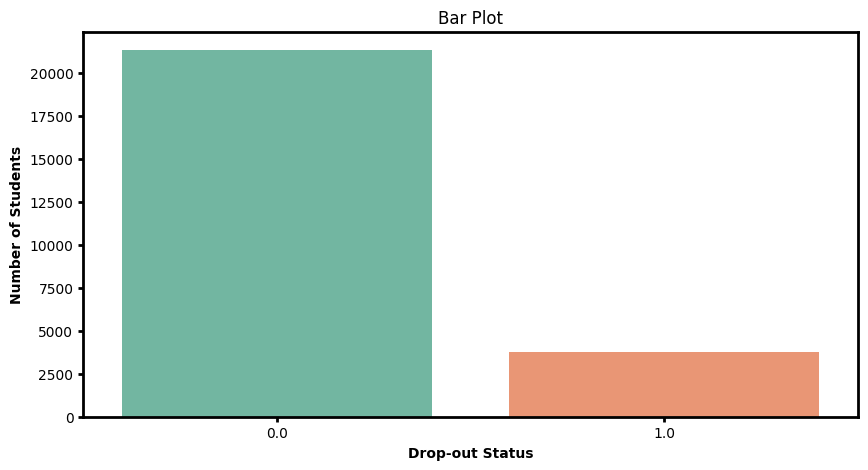

In [ ]:
plt.figure(figsize=(10, 5))
axes=sns.countplot(data=data_stage1_5, x='DropOut', hue='DropOut', palette='Set2',legend=False)
axes.tick_params(width=2)
for pos in ['top','bottom','left','right']:
    axes.spines[pos].set_linewidth(2)

plt.xlabel('Drop-out Status',fontweight='bold')
plt.ylabel('Number of Students',fontweight='bold')
plt.title('Bar Plot')
plt.savefig('target_barplot_s1.svg')
plt.show()


In [ ]:
# Compute the ratio
data_stage1_5.DropOut.value_counts(normalize=True)

,proportion
DropOut,
0.0,0.850194
1.0,0.149806


The ratio of students who did dropout to those who did not dropout is ~5.7 which indicates the dataset is imbalanced towards the negative class (DropOut='0').

## Pre-processing Variables for Model Training

### 1.2 A Perform the Train-Test Split

In [ ]:
# Target variable:
y_s1=data_stage1_5['DropOut']

# Input Features:
X_s1=data_stage1_5.drop(columns='DropOut')

In [ ]:
# Split the data into train, test and validation sets.
X_train_full_s1, X_test_s1, y_train_full_s1, y_test_s1 = train_test_split(X_s1, y_s1, stratify=y_s1, test_size=0.2, random_state=42)
X_train_s1, X_valid_s1, y_train_s1, y_valid_s1 = train_test_split(X_train_full_s1, y_train_full_s1, stratify=y_train_full_s1, test_size=0.1, random_state=42)

# Here, stratify parameter ensures that the training and testing sets have the same proportion of classes

### 1.2 B Perform scaling on the split datasets

In [ ]:
data_stage1_5[['Age','CourseLevel']].describe()

,Age,CourseLevel
count,25059.000000,25059.000000
mean,25.418971,0.887905
std,3.175703,1.231749
min,20.000000,0.000000
25%,23.000000,0.000000
50%,25.000000,0.000000
75%,27.000000,1.000000
max,63.000000,3.000000


As the two numerical features 'Age' and 'CourseLevel' have very different ranges (20-63 and 0-3 respectively) it is important to scale the data for processing with a neural network, such that the assigned weight of a given input feature is not affected by the magnitude of its range. As tree-based ensemble techniques determine features with which to perform patitions based on thresholds (either a measure of accuracy or impurity), the scaling step is not necessary for the XGBoost model.

In [ ]:
# Apply  Standard Scaler only on the numeric features that are not 0s and 1s (continuous)
col_list= ["Age","CourseLevel"]
scaler = StandardScaler()
ct = ColumnTransformer([('num_preprocess', scaler, col_list)], remainder='passthrough')
X_train_scaled_s1= ct.fit_transform(X_train_s1)
X_valid_scaled_s1 = ct.transform(X_valid_s1)
X_test_scaled_s1 = ct.transform(X_test_s1)

The one-hot encoded categorical features are already bound within the [0,1] range. Thus, applying standard scaling will convert the 0s into a negative number and 1s into a positive number such that a mean of 0 and a standard deviation of 1 is obtained. For different features, this means a different negative and a different positive value which can result in loss of inter-feature interpretability. Therefore, to preserve the intrinsicness across the related categorical variables that have been one-hot encoded, it would be safer (in terms of data leakage and consistency) to preserve the one-hot encoded categorical features as binary.

## XGBoost Classification for Stage 1

### 1.3 A Create and Train a Baseline XGBoost Model

The XGBoost has several tunable hyperparameters of which the following three would be high-priority:

* 'n_estimators': Sets the number of trees in the ensemble where the default is '100'. Too low a value risks underfitting, while too high wastes computational resources.
* 'max_depth': Restricts the number of levels that the tree can have. The maximum depth can take on an integer value or default to 'None', allowing the tree to reach its maximum possible depth.
* 'learning_rate': Controls step size shrinkage used in (learner) update to prevent overfitting. The full range for this parameter is [0,1] but it typically ranges from 0.01 to 0.3. Lower values create robust models but require longer training while higher values speed up training but risk overfitting.

In [ ]:
# Create a XGBoost Model with an objective of binary classification
xgb_basemodel_s1 = XGBClassifier(
    objective='binary:logistic',
    n_estimators=100,
    max_depth=10,
    learning_rate=0.01,
)

In the proposed model, the max_depth is set relatively high considering the dataset has 389 input features, implying a highly complex structure is expected to result from various partitionings. The goal here is to capture the right level of complexity while avoiding overfitting.

In [ ]:
# Train the XGBoost Model
xgb_basemodel_s1.fit(X_train_scaled_s1, y_train_s1)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.01, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=10,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# Make predictions
y_pred_s1_xgb_base = xgb_basemodel_s1.predict(X_test_scaled_s1)

# Evaluate the model
accuracy = accuracy_score(y_test_s1, y_pred_s1_xgb_base)
AUC = roc_auc_score(y_test_s1, y_pred_s1_xgb_base)

# Print the evaluation metrics.
print("Accuracy:", accuracy)
print("AUC:", AUC)

Accuracy: 0.8754988028731046
AUC: 0.6174600649810266


In [ ]:
# Classification Report
xgb_s1_base_report=classification_report(y_test_s1,y_pred_s1_xgb_base)
print(xgb_s1_base_report)

              precision    recall  f1-score   support

         0.0       0.88      0.99      0.93      4261
         1.0       0.76      0.25      0.37       751

    accuracy                           0.88      5012
   macro avg       0.82      0.62      0.65      5012
weighted avg       0.86      0.88      0.85      5012



Interpretation of the evaluation metrics:

* Accuracy : gives us total correct guesses out of all the guesses.
* Precision : how many correct predictions out of all predictions for a specific class?
* Recall: how many actual record of a class correctly predicted? This is equivalent to sensitivity.
* F1 Score: calculates the harmonic mean of precision and recall.
* AUC Score: Conceptually, represents the probability that a model, if given a randomly chosen positive and negative sample, will rank the positive higher than the negative.

Based on the basic metric inrerpretations listed above, the baseline model is able to produce correct predictions at an overall rate of 88 %, as given by the accuracy. However, when considering the AUC score, it can be argued that these predictions are only slightly better than random guesses (AUC = 0.62 > 0.50) and the model is likely favouring one class over the other, as also suggested by the recall scores. Considering the dataset contains a significantly higher percentage of the nagative class  (Dropout: No or label '0'), the 'favoured' class in this case is the negative class.

### 1.3 B Confusion Matrix and Analysis

In [ ]:
# Create confusion matrix
cm_s1_xgb_base= confusion_matrix(y_test_s1, y_pred_s1_xgb_base)


In [ ]:
# Function to customize confusion matrix labels
def matrix_labels(cm):
  cm_names=["TN","FP","FN","TP"]
  cm_counts = cm.flatten()
  cm_percentages =[f'{perc:.2f}%' for perc in (cm/np.sum(cm, axis=1, keepdims=True)*100).flatten()]
  ini_labels = [f'{v1} \n {v2} \n {v3}' for v1, v2, v3 in zip(cm_names,cm_counts,cm_percentages)]
  cm_labels = np.asarray(ini_labels).reshape(2,2)
  return cm_labels

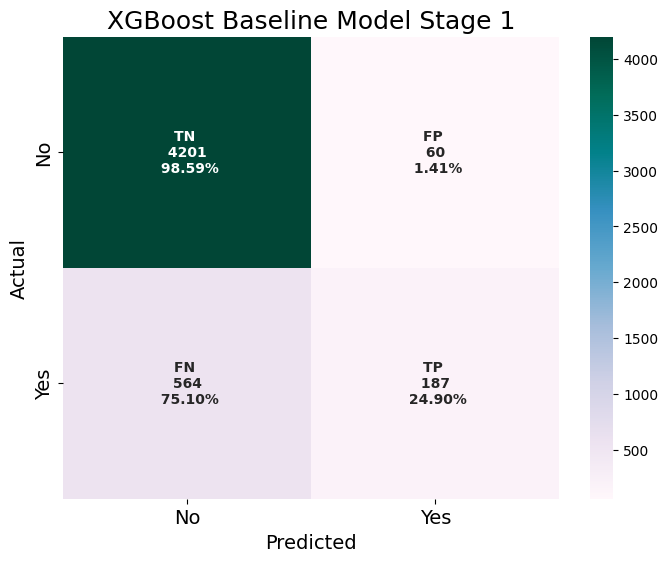

In [ ]:
# Display resulting confusion matrix
cm_labels_s1_xgb_base= matrix_labels(cm_s1_xgb_base)

plt.figure(figsize=(8,6))
plt.rcParams["font.weight"] = "normal"
ax=sns.heatmap(cm_s1_xgb_base, annot=cm_labels_s1_xgb_base,annot_kws={"fontweight":'bold'},fmt='', cmap='PuBuGn')
ax.xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
ax.yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
#plt.rc('font', weight='normal', size=14)
plt.xlabel('Predicted',fontsize=14)
plt.ylabel('Actual',fontsize=14)
plt.title('XGBoost Baseline Model Stage 1',fontsize=18)


* Considering all the students that **did not** dropout, 98.6% have been correctly classified as a non-dropout whereas 1.4% have been falsely classified as a dropout.

* Now focussing on all the students that actually **did** dropout, 75.1%  have been falsely classified as a non-dropout and 24.9% has been correctly classified as a dropout.

* This is also reflected in the classification report where the recall for the positive class is 0.25 and the negative class is 0.99, suggesting the model is not very sensitive to the positive class.

* This may be expected as the dataset is skewed towards the negative class where for every student that did dropout, there are 5 to 6 students that did not.

* The imbalance in the dataset also means that the ROC-AUC score is a more suitable evaluation/scoring metric for hyperparameter tuning.


### 1.3 C Tune the XGBoost Model

In [ ]:
# Hyperparameter search space for a Grid or Random search
xgb_grid1_s1 = {"n_estimators":range(50,300,50),"max_depth":range(5,20,5), "learning_rate":[0.001,0.01,0.05,0.1,0.2]}



The above search grid gives 4 x 3 x 5 = 60 hyperparamaters to tune which is manageable with a grid search approach.

In [ ]:
# Tune using Grid Search with 10-fold cross-validation
xgb_grid_search_s1 = GridSearchCV(XGBClassifier(random_state=42), param_grid= xgb_grid1_s1,cv=10,scoring='roc_auc',n_jobs=-1)
xgb_grid_search_s1.fit(X_train_scaled_s1, y_train_s1)



GridSearchCV(cv=10,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=No...
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.001, 0.01, 0.05, 0.1, 0.2],
                         'max_depth': range(5, 20, 5),
                         'n_estimators': range(50, 250, 50)},
             scoring='roc_auc')

In [ ]:
# Print search results
best_xgb_grid_s1 = xgb_grid_search_s1.best_params_

print("Best Parameters:", best_xgb_grid_s1)
print("Best Accuracy Score:", round(xgb_grid_search_s1.best_score_ , 3))

Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 150}
Best Accuracy Score: 0.882


In [ ]:
# Build model with best parameters
# xgb_bestmodel_grid_s1=xgb_grid_search_s1.best_estimator_

# To avoid having to re-run the tuner let's use the best params that resulted
xgb_bestmodel_grid_s1=XGBClassifier(
    objective='binary:logistic',
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
)

xgb_bestmodel_grid_s1.fit(X_train_scaled_s1, y_train_s1)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=150,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# Predict with this model
y_pred_s1_xgb_grid=xgb_bestmodel_grid_s1.predict(X_test_scaled_s1)

As the hyperparameter search grid is limited to a predefined set of values, an alternative tuning approach such as Bayesian optimization can be implemented to make sure the optimal model configuration is not completely missed.

Bayesian optimization is a sequential model-based optimization (SMBO) algorithm that incorporates Bayesian statistics to predict promising hyperparameters in fewer iterations [insert references].

It works by building a probabilistic model of the objective function -model performance- based on tested hyperparameter values.

This probabilistic model is referred to as a surrogate of the original objective function which for every hyperparameter configuration predicts the model performance and provides a measure of the uncertainty associated with that prediction.

As the model is updated and improved after every execution, it is more efficient than a grid or a randomized search.

This allows for the trial of an expanded range of hyperparameter values in a significantly less time than it would take for a grid search.  

In [ ]:
#  Hyperparameter search space for the Bayesian search
xgb_grid2_s1={
    'n_estimators': Integer(50, 250, prior='uniform'),
    'max_depth': Integer(5, 20,prior='uniform'),
    'learning_rate': Real(0.001, 0.3,prior='log-uniform'),
}

Note that, as a probabilistic model is being created in the process, the hyperparameters need to be defined with a prior distribution. For example, 'log-uniform' implies search over p = exp(x) by varying x.

In [ ]:
# create an instance of the Bayesian search object
xgb_bayes_search_s1 = BayesSearchCV(XGBClassifier(random_state=42), xgb_grid2_s1, cv=5, n_iter=120, random_state=42, scoring='roc_auc',n_jobs=-1)

# conduct randomized search over the parameter space
xgb_bayes_search_s1.fit(X_train_scaled_s1, y_train_s1)

BayesSearchCV(cv=5,
              estimator=XGBClassifier(base_score=None, booster=None,
                                      callbacks=None, colsample_bylevel=None,
                                      colsample_bynode=None,
                                      colsample_bytree=None, device=None,
                                      early_stopping_rounds=None,
                                      enable_categorical=False,
                                      eval_metric=None, feature_types=None,
                                      feature_weights=None, gamma=None,
                                      grow_policy=None, importance_type=None,
                                      interaction_constraints=No...
                                      multi_strategy=None, n_estimators=None,
                                      n_jobs=None, num_parallel_tree=None, ...),
              n_iter=120, n_jobs=-1, random_state=42, scoring='roc_auc',
              search_spaces={'learning_rate': Real(low=0.001, high=0.3, prior='log-uniform', transform='normalize'),
                             'max_depth': Integer(low=5, high=20, prior='uniform', transform='normalize'),
                             'n_estimators': Integer(low=50, high=250, prior='uniform', transform='normalize')})

Given the Bayesian approach performs an intelligent search, the number of configurations to be tested can be doubled. However, as it has to learn from the prior execution of the objective function, more computational resources are required. To bypass this caveat, the optimisation is performed with 5-fold cross-validation as opposed to 10.

In [ ]:
# Print search results
best_xgb_bayes_s1 = xgb_bayes_search_s1.best_params_

print("Best Parameters:", best_xgb_bayes_s1)
print("Best Accuracy Score:", round(xgb_bayes_search_s1.best_score_ , 3))

Best Parameters: OrderedDict({'learning_rate': 0.11149685840108765, 'max_depth': 5, 'n_estimators': 216})
Best Accuracy Score: 0.883


Both techniques agree on the learning_rate ( with Bayesian optimisation returning a more precise value) and the max_depth, but differ on the n_estimators : 150 selected by the grid search and 216 by the Bayesian optimisation algorithm. As the Bayesian optimisation relies on a probabilistic approach to test a fixed number of configurations from an extended pool of hyperparameters with 5-fold cross-validation, the final configuration can vary after each run especially when it comes to the n_estimators parameter.  

In [ ]:
# Build model with best parameters
# xgb_bestmodel_bayes_s1=xgb_bayes_search_s1.best_estimator_
# To avoid having to re-run the tuner let's use the best params that resulted
xgb_bestmodel_bayes_s1=XGBClassifier(
    objective='binary:logistic',
    n_estimators=216,
    max_depth=5,
    learning_rate=0.11,
)

xgb_bestmodel_bayes_s1.fit(X_train_scaled_s1, y_train_s1)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.11, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=216,
              n_jobs=None, num_parallel_tree=None, ...)

 Compare the two sets of evaluation metrics that result from the two searches:

In [ ]:
# Function to compare classification reports
def class_reports(models,model_names,X_test,y_test):
  dict_list = []
  for model,name in zip(models,model_names):
    # Make predictions
    y_pred_model=model.predict(X_test)

    report = classification_report(y_test, y_pred_model, output_dict=True)
    ROC_AUC=roc_auc_score(y_test, y_pred_model)

    # Compute accuracy, precision, recall, F1 score, and ROC-AUC.
    row_dict={'Model':name,
              'Accuracy':report['accuracy'],
              'Precision':report['macro avg']['precision'],
              'Recall':report['macro avg']['recall'],'F1 Score':report['macro avg']['f1-score'],
              'ROC-AUC':ROC_AUC}

    # Output to dictionary row-by-row
    dict_list.append(row_dict)
  return dict_list


In [ ]:
# Run the models and output classification report metrics into a dataframe
models=[xgb_basemodel_s1,xgb_bestmodel_grid_s1,xgb_bestmodel_bayes_s1]
model_names=['Baseline XGBoost Model', 'Post Grid Search','Post Bayesian Optimisation']
dict_list=class_reports(models,model_names,X_test_scaled_s1,y_test_s1)

In [ ]:
df_report_xgb_s1= pd.DataFrame.from_dict(dict_list)
df_report_xgb_s1

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline XGBoost Model,0.875499,0.819361,0.617460,0.652808,0.617460
1,Post Grid Search,0.894852,0.804072,0.754434,0.775698,0.754434
2,Post Bayesian Optimisation,0.894653,0.802700,0.756511,0.776518,0.756511


While hyperparamter tuning with both the grid search and the Bayesian optimisation improves classification performance, the difference in improvement between the simplistic grid search approach and the computationally more demading Bayesian optimisation is marginal. Therefore, despite the hyperparameter configuration returned by Bayesian optimisation being the optimal, the XGBoost model will be built with the hyperparameters returned by the grid search, such that more direct comparisons can be drawn towards the latter stages.

### 1.3 D Post-Tuning Classification Report and Analysis

In [ ]:
# Create confusion matrix
cm_s1_xgb_grid= confusion_matrix(y_test_s1, y_pred_s1_xgb_grid)


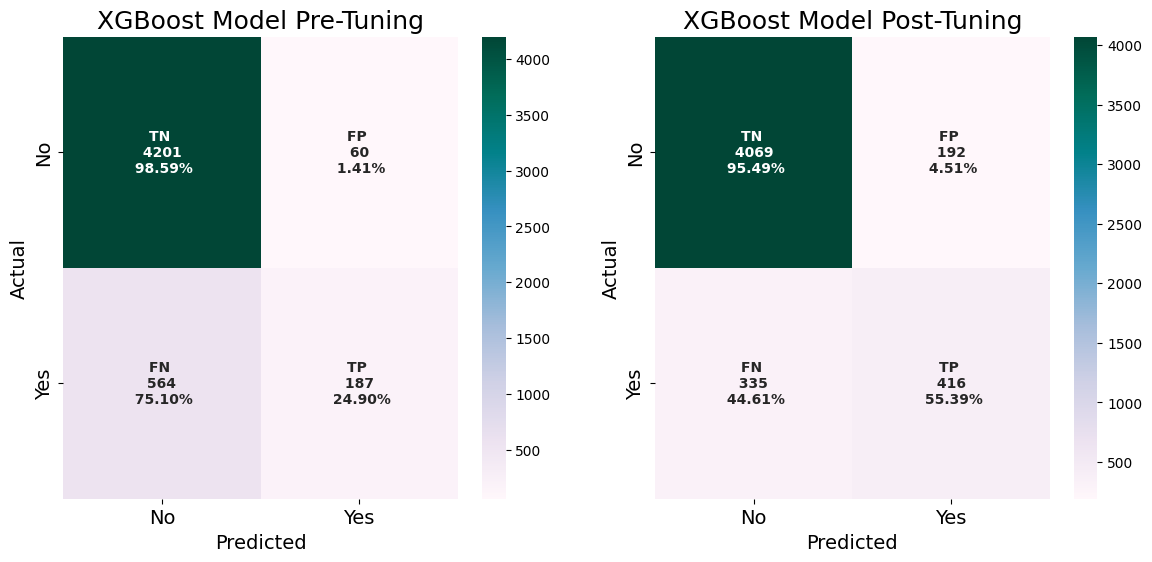

In [ ]:
# Display resulting confusion matrix
cm_labels_s1_xgb_grid= matrix_labels(cm_s1_xgb_grid)

fig, axes = plt.subplots(1, 2, figsize=(14,6))

sns.heatmap(cm_s1_xgb_base, annot=cm_labels_s1_xgb_base,annot_kws={"fontweight":'bold'}, fmt='', cmap='PuBuGn',ax=axes[0])
sns.heatmap(cm_s1_xgb_grid, annot=cm_labels_s1_xgb_grid,annot_kws={"fontweight":'bold'}, fmt='', cmap='PuBuGn',ax=axes[1])

for i in range(2):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)
axes[0].set_title('XGBoost Model Pre-Tuning',fontsize=18)
axes[1].set_title('XGBoost Model Post-Tuning',fontsize=18)


* A comparision of the classification metrics between the base and tuned model shows a significant improvement upon hyperparameter tuning.

* The XGBoost model is now able classify 55.4% of the actual dropout cases correctly compared to only 24.9% before which is more than double.

* Essentially a trade-off is made between sensitivity (TPR) and specificity(TNR) with the model now made more sensitive to the positive class (the dropout cases).

* The tuned model uses a max_depth of 5 which is half the proposed depth for the initial model, as well as a learning_rate of 0.1 which is an order of magnitude higher than the initial model. Thus by incorparating more estimators/ learners, the tuned model is able to update faster and increase gain with less splits.



### 1.3 E Feature Importance

Below is a the feature importance plot depicting the 20 features/attributes that are most strongly contributing towards the model's predictive power in terms of improving accuracy.

In [ ]:
# Create bar plot of top 20 features
feature_importance_s1 = pd.Series(xgb_bestmodel_grid_s1.feature_importances_, index=X_train_s1.columns).sort_values()

axes=feature_importance_s1.iloc[-20:].plot.barh()
axes.tick_params(width=2)

for pos in ['top','bottom','left','right']:
  axes.spines[pos].set_linewidth(2)


While feature importance gives an indication of how the model performance - in this case, increase in gain- improves by that feature's split point, it does not inform of the actual effect that a said feature has on the outcome variable (student dropout). Thus, based on this plot one cannot argue that students that has certain nationalities, registered in certain courses or has joined the programme through certain centres are at more risk of dropout. The only objective argument that can be made is that these top attributes help the model make better predictions.



In [ ]:
# Function to check percentage of dropouts for a given feature
def percentage_dropout(feature,dataset):
  feature_dropout=dataset[(dataset[feature] == 1) & (dataset['DropOut']==1)]
  dropout_count=len(feature_dropout)
  total_count=len(dataset[dataset[feature] == 1])
  return round((dropout_count/total_count)*100,2)


To prove this point, the percentage of dropouts for the top 5 features can be calculated using the helper function above. It can be seen that the top 5 features have different rankings when it comes to the percentage of dropouts for that given attribute. For instance, "RedactedFeature" ranks 4th in feature importance but 2nd when it comes to the percentage of students who has droppedout. Intuitively, one can expect the relative percentage dropout for these features to be very high, however, this is not necessarily the case.

In [ ]:
for i in range(-5,0):
  feature=feature_importance_s1[feature_importance_s1==feature_importance_s1.iloc[i]].index[0]
  print(f"{feature}: {percentage_dropout(feature,data_stage1_5)}%")

## Neural Network Implementation for Stage 1

### 1.4.A Developing a Baseline for the Neural Network Architechture

**Starting Criteria:**
* An Input layer with number of neurons equal to the number of features.

* Two or more hidden layers - predicting student behaviour based on the set of features provided presents with a level of complexity that requires developing a model that learns patterns over several layers, as oposed to extracting patterns directly from the input data itself.

* ReLU activation for the hidden layers - ReLU function not only offers computational efficieny and simplicity but also resists the vanishing gradient problem. The hyperbolic tangent function can be chosen as an alternative.

* An output layer with one neuron and sigmoid activation, considering the objective is binary classification.  

* A loss function of binary cross entropy as it offers a mathematically elegant way of quantifying the difference between predicted probabilities (0 to 1) and actual binary labels.

* Adam optimiser implemented in the gradient descent as it incorporates momentum with an adjusted learning rate.

**Model Development Strategy**: A stragey that can be used is to start with a simple model architecture and increase complexity incrementally based on the resulting trends in metrics being  monitored.

> * For instance, the model can be instantiated with 4 hidden layers, with the width of these hidden layers kept relatively small. Starting from an input dimension of 389, the consequent hidden layers can have 128, 64, 32 and 16 neurons respectively.

> * A second option may be to start with 64 neurons per layer and increase the number of layers depending on model performance.

> * A third option may be to follow a linearly decreasing number of neurons based on the input and output layer widths, in a bottleneck fashion.

* As the first option proposed is a hybrid between the latter two, let's create the baseline model with 4 hidden layers (giving a total of 6 layers) and with the nodes distributed sequentially, i.e. [128,64,32,16] neurons per consecutive hidden layer.

* Both the number of hidden layers and the number of neurons per layer will need to be optimised within a hyperparameter space that also includes regularisation, choice of activation function and learning rate.


In [ ]:
# Define a function to create the baseline model
def baseline_model_s1(input_dim):

  model= Sequential([
          Input(shape=(input_dim,),name='input'),  # Input  layer
          layers.Dense(128, activation='relu',name='hidden_1'), # Hidden layer 1
          layers.Dense(64, activation='relu',name='hidden_2'),  # Hidden layer 2
          layers.Dense(32, activation='relu',name='hidden_3'),  # Hidden layer 3
          layers.Dense(16, activation='relu',name='hidden_4'),  # Hidden layer 4
          layers.Dense(1, activation='sigmoid',name='output')   # Output layer
                     ],name='baseline_model')

  model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['AUC'])

  return model

In [ ]:
NN_model_baseline_s1= baseline_model_s1(X_train_s1.shape[1])
NN_model_baseline_s1.summary()

Model: "baseline_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_4 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,801 (237.50 KB)

 Trainable params: 60,801 (237.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train and visualise the learning performance.

history_baseline_s1 = NN_model_baseline_s1.fit(X_train_scaled_s1, y_train_s1, epochs=12, batch_size=32, validation_data=(X_valid_scaled_s1, y_valid_s1), verbose=0)


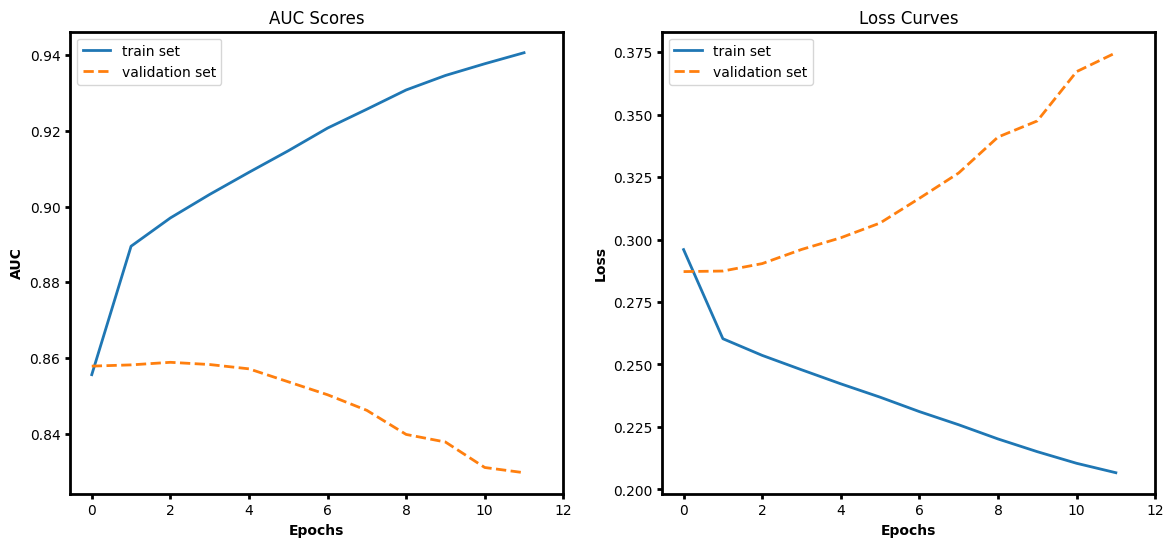

In [ ]:
# Visualise the loss and accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(14,6))
# Plot accuracy.
axes[0].plot(history_baseline_s1.history['AUC'],linewidth=2,label='train set')
axes[0].plot(history_baseline_s1.history['val_AUC'],linestyle='--',linewidth=2,label='validation set')
custom_ticks = list(range(0,14,2))
axes[0].xaxis.set_ticks(custom_ticks)
axes[0].set_title('AUC Scores')
axes[0].set_xlabel('Epochs',fontweight='bold')
axes[0].set_ylabel('AUC',fontweight='bold')
axes[0].legend()

# Plot loss.
axes[1].plot(history_baseline_s1.history['loss'],linewidth=2,label='train set')
axes[1].plot(history_baseline_s1.history['val_loss'],linestyle='--',linewidth=2,label='validation set')
axes[1].xaxis.set_ticks(custom_ticks)
axes[1].set_title('Loss Curves')
axes[1].set_xlabel('Epochs',fontweight='bold')
axes[1].set_ylabel('Loss',fontweight='bold')
axes[1].legend()

for i in range(2):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)


The AUC and loss plots obtained for the train and validation sets are indicative of overtraining where the AUC score for the training set constantly increases (up to 0.94 which is very close to a perfect score of 1) while the AUC plot for the validation set diverges in the opposite direction. The loss curve for the train set is rapidly decreasing after every epoch whereas the opposite is true for the validation set. In otherwords, the current deep learning model presents with a case of Low Bias and High Variance.

In [ ]:
# Evaluate the baseline model.
train_loss, train_accuracy = NN_model_baseline_s1.evaluate(X_train_scaled_s1, y_train_s1, verbose=0)
test_loss, test_accuracy = NN_model_baseline_s1.evaluate(X_test_scaled_s1, y_test_s1, verbose=0)

print('Train accuracy:',train_accuracy)
print('Test accuracy:',test_accuracy)
print('Train loss:', train_loss)
print('Test loss:', test_loss)



Train accuracy: 0.9395219087600708
Test accuracy: 0.8505249619483948
Train loss: 0.2103433758020401
Test loss: 0.33052653074264526


While a low test accuracy may be expected due to overfitting, it must be noted that the accuracy represents the ratio of correct number of predictions to total number of predictions regardless of class. Thus, it is likely that the model is skewed towards the negative class (no dropout) which is more prevalent in the dataset, overall returning a relatively high test accuracy.

In [ ]:
# Use the trained model to perform predictions on the X_test data set.
y_pred_s1= NN_model_baseline_s1.predict(X_test_scaled_s1)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [ ]:
# Convert model prediction probabilties to binary
y_pred_s1_baseline= (y_pred_s1 > 0.5).astype('int')

In [ ]:
# Print the full set of evaluation metrics.

report_s1_baseline= classification_report(y_test_s1, y_pred_s1_baseline)
ROC_AUC=roc_auc_score(y_test_s1, y_pred_s1_baseline)

print(report_s1_baseline)
print("AUC:", ROC_AUC)

              precision    recall  f1-score   support

         0.0       0.92      0.96      0.94      4261
         1.0       0.68      0.52      0.59       751

    accuracy                           0.89      5012
   macro avg       0.80      0.74      0.76      5012
weighted avg       0.88      0.89      0.88      5012

AUC: 0.7372794968517296


The classification metrics prove the 'class-bias' point where we have a high recall on the negative class (non-dropout cases) but a recall of 50% on the positive class (dropout cases). The overall AUC score indicates that the predictions are not made at random but would not be considered high enough if the classification problem involved a medical scenario. For the purpose of correctly predicting students at risk of dropout (from their respective programmes), a score of 0.75 may be considered acceptable.

### 1.4.B Confusion Matrix and Preliminary Analysis of the Baseline Model

In [ ]:
# Create confusion matrix

cm_s1_NN_base= confusion_matrix(y_test_s1, y_pred_s1_baseline)


The confusion matrix suggests of the students that **did not** dropout over 95% have been classified correctly whereas of the students that **did** dropout roughly 50% have been classified correctly by the deep learning model. The negative and positive class recall scores are already very close to the hyperparameter-tuned XGBoost model but as was the case with the XGBoost classifier, further improvement may be possible upon hyper-parameter tuning.

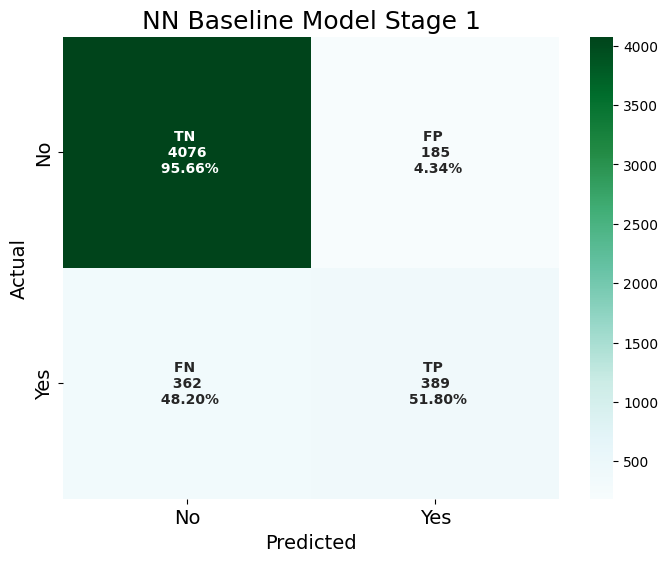

In [ ]:
cm_labels_s1_NN_base= matrix_labels(cm_s1_NN_base)
plt.figure(figsize=(8,6))
ax=sns.heatmap(cm_s1_NN_base, annot=cm_labels_s1_NN_base, annot_kws={"fontweight":'bold'},fmt='', cmap='BuGn')
ax.xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
ax.yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
plt.xlabel('Predicted',fontsize=14)
plt.ylabel('Actual',fontsize=14)
plt.title('NN Baseline Model Stage 1',fontsize=18)

### 1.4.C Tuning the Deep Neural Network Model

**Using the HyperBand Approach:**

* Considering the dataset is relatively large and the neural network structure relatively complex, a Bayesian approach would be computationally expensive in this scenario.

* A grid search with so many hyperparameters to tune would prove inefficient which leaves randomized search as an alternative. However, a more efficient alternative to a randomized search is the Hyperband approach.

* The Hyperband tuning algorithm combines *Successive Halving* with adaptive resource allocation, where the resources are intelligently allocated to competing hyperparameter configurations based on how well they are peforming.

* Several configurations are tested with low resources and those that seem promising are allocated increasingly higher resources after every round. In other words, the number of trials are successively halved until a single configuration that has consistently outperformed others remains.  

* By also incorporating early stopping, several poor performing configurations can be eliminated at the initial stages which means an extended hyperparameter space can be searched efficiently.


To search the proposed hyperparameter space using HyperBand approach, an automated tuner called the Keras Tuner will be implemented.

In [ ]:
# Hyperparameter tuning using Keras tuner

def model_builder_s1(hp):
    # Initialize sequential API and start building model.
    model = Sequential(name='HB_model')
    # Add input layer
    model.add(Input(shape=(X_train_s1.shape[1],)))

    # Tune the number of hidden layers and units in each.

    # Number of hidden layers: 2-8 (total number of layers: 1-10)
    # Number of Units: 16 - 256 with stepsize of 16

    # Provide a choice of activation function:
    hp_activation = hp.Choice('activation', values=['relu', 'tanh'])

    for i in range(2,hp.Int("num_layers", 2, 9)):
        model.add(
                Dense(
                units=hp.Int("units_" + str(i), min_value=32, max_value=256, step=16),
                activation=hp_activation,name ="hidden_layer_"+ str(i-1))
            )
    # add name

    # Add output layer.
    model.add(Dense(units=1, activation="sigmoid"))

    # Provide a choice of optimizer
    hp_optimizer = hp.Choice("optimizer", values=['Adam', 'RMSprop'])

    # Tune learning rate for chosen optimizer with values from 0.1 to 0.0001
    hp_lr = hp.Float("learning_rate", min_value=0.0001, max_value=0.1, step=10, sampling="log")

    if hp_optimizer == 'RMSprop':
      optimizer = RMSprop(learning_rate=hp_lr)
    elif hp_optimizer == 'Adam':
      optimizer = Adam(learning_rate=hp_lr)

    # Define optimizer, loss, and metrics
    model.compile(optimizer=optimizer,
                  loss='binary_crossentropy',
                  metrics=["AUC"])

    # Return compiled model with hyperparameters to tune
    return model

In [ ]:
# print(list(range(16,400,16)))

In [ ]:
# Instantiate the hyperparameter tuner with the Hyperband approach
tuner_HB = kt.Hyperband(model_builder_s1,
                     objective=kt.Objective("val_AUC", direction="max"),
                     max_epochs=24, # set epochs relatively high for an extensive search
                     factor=3,
                     overwrite=True,
                     directory='dir',
                     project_name='hp_tuning',
                     seed=42,
                     )

In [ ]:
tuner_HB.search_space_summary()

Search space summary
Default search space size: 4
activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 2, 'max_value': 9, 'step': 1, 'sampling': 'linear'}
optimizer (Choice)
{'default': 'Adam', 'conditions': [], 'values': ['Adam', 'RMSprop'], 'ordered': False}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.1, 'step': 10, 'sampling': 'log'}


In [ ]:
# Add early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, verbose=0, mode='min', restore_best_weights=True)

In [ ]:
# Perform the search
tuner_HB.search(X_train_scaled_s1, y_train_s1, epochs=24, batch_size=32, validation_data=(X_valid_scaled_s1, y_valid_s1), callbacks=[early_stopping])

Trial 30 Complete [00h 00m 27s]
val_AUC: 0.8617439270019531

Best val_AUC So Far: 0.8641847372055054
Total elapsed time: 00h 10m 56s


In [ ]:
# Get the best hyperparamter configuration
best_hps_HB = tuner_HB.get_best_hyperparameters(num_trials=1)[0]

The following is the hyperparameter configuration that the Hyperband algorithm determined to be the best based on validation AUC score.

In [ ]:
best_hps_HB.values

{'activation': 'tanh',
 'num_layers': 9,
 'optimizer': 'RMSprop',
 'learning_rate': 0.0001,
 'units_2': 160,
 'units_3': 128,
 'units_4': 48,
 'units_5': 96,
 'units_6': 240,
 'units_7': 112,
 'units_8': 112,
 'tuner/epochs': 8,
 'tuner/initial_epoch': 0,
 'tuner/bracket': 1,
 'tuner/round': 0}

The Hyperband function determined that 7 hidden layers with a respective neuron counts of [160,128,48,96,240,112,112] and with an activation function of 'tanh' has outformed the other probable configurations that were tested. The selected optimiser is 'RMSprop' with a learning rate of 0.0001- typically the default setting is 0.001. While the resulting model architecture and the choice of activation and optimizer functions are vastly different than the arbitrarily created baseline model, it must be noted that the current configuration is not a global maximum for the objective function. Although non-stochastic, the Hyperband algorithm is still an explorative approach that utilises aggressive early pruning and may miss out on initial strong configurations that converge slowly. Thus, the proposed configuration may be considered strong but may not be the optimal or the only solution.

In [ ]:
model_HB_s1=tuner_HB.hypermodel.build(best_hps_HB)
model_HB_s1.summary()

Model: "HB_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 160)            │        62,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 128)            │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_3 (Dense)          │ (None, 48)             │         6,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_4 (Dense)          │ (None, 96)             │         4,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_5 (Dense)          │ (None, 240)            │        23,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_6 (Dense)          │ (None, 112)            │        26,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_7 (Dense)          │ (None, 112)            │        12,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           113 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 156,945 (613.07 KB)

 Trainable params: 156,945 (613.07 KB)

 Non-trainable params: 0 (0.00 B)

For consistency, will create a function for the Hyperband tuned model such that it can also be used as a baseline model for the Stage 2 dataset.

In [ ]:
# Define a function to create the baseline model
def baseline_model_s2(input_dim):

  model= Sequential([
          Input(shape=(input_dim,),name='input'),  # Input  layer
          layers.Dense(160, activation='tanh',name='hidden_1'), # Hidden layer 1
          layers.Dense(128, activation='tanh',name='hidden_2'),  # Hidden layer 2
          layers.Dense(48, activation='tanh',name='hidden_3'),  # Hidden layer 3
          layers.Dense(96, activation='tanh',name='hidden_4'),  # Hidden layer 4
          layers.Dense(240, activation='tanh',name='hidden_5'),  # Hidden layer 5
          layers.Dense(112, activation='tanh',name='hidden_6'),  # Hidden layer 6
          layers.Dense(112, activation='tanh',name='hidden_7'),  # Hidden layer 7
          layers.Dense(1, activation='sigmoid',name='output')   # Output layer
      ],name='baseline_model')

  model.compile(optimizer=RMSprop(learning_rate=0.0001),
                  loss='binary_crossentropy',
                  metrics=['AUC'])

  return model

In [ ]:
# Train and visualise the learning performance.
NN_model_HB_s1=baseline_model_s2(X_train_s1.shape[1])
# NN_model_HB_s1.summary()
history_HB_s1 = NN_model_HB_s1.fit(X_train_scaled_s1, y_train_s1, epochs=12, batch_size=32, validation_data=(X_valid_scaled_s1, y_valid_s1), verbose=0)


### 1.4.D Post-Tuning Performance and Analysis

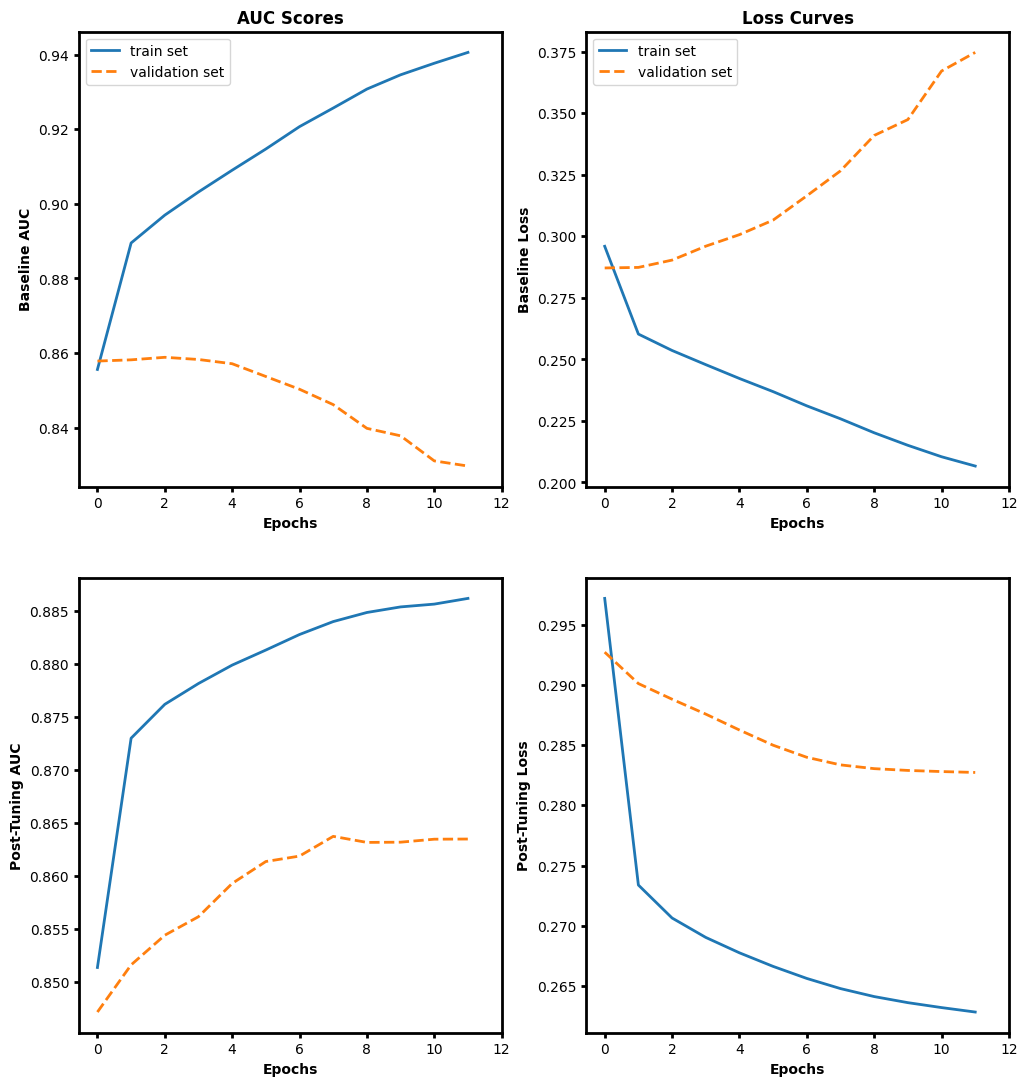

In [ ]:
# Visualise the loss and accuracy curves
fig, axes = plt.subplots(2, 2, figsize=(12,13))
axes.shape
# Plot accuracy.
axes[0,0].plot(history_baseline_s1.history['AUC'],label='train set',linewidth=2)
axes[0,0].plot(history_baseline_s1.history['val_AUC'],linestyle='--',label='validation set',linewidth=2)
custom_ticks = list(range(0,14,2))
axes[0,0].xaxis.set_ticks(custom_ticks)
axes[0,0].set_title('AUC Scores',fontweight='bold')
axes[0,0].set_xlabel('Epochs',fontweight='bold')
axes[0,0].set_ylabel('Baseline AUC',fontweight='bold')
axes[0,0].legend()

# Plot loss.
axes[0,1].plot(history_baseline_s1.history['loss'],label='train set',linewidth=2)
axes[0,1].plot(history_baseline_s1.history['val_loss'],linestyle='--',label='validation set',linewidth=2)
axes[0,1].xaxis.set_ticks(custom_ticks)
axes[0,1].set_title('Loss Curves',fontweight='bold')
axes[0,1].set_xlabel('Epochs',fontweight='bold')
axes[0,1].set_ylabel('Baseline Loss',fontweight='bold')
axes[0,1].legend()

# Plot accuracy.
axes[1,0].plot(history_HB_s1.history['AUC'],linewidth=2)
axes[1,0].plot(history_HB_s1.history['val_AUC'],linestyle='--',linewidth=2)
axes[1,0].xaxis.set_ticks(custom_ticks)
axes[1,0].set_xlabel('Epochs',fontweight='bold')
axes[1,0].set_ylabel('Post-Tuning AUC',fontweight='bold')

# Plot loss.
axes[1,1].plot(history_HB_s1.history['loss'],linewidth=2)
axes[1,1].plot(history_HB_s1.history['val_loss'],linestyle='--',linewidth=2)
axes[1,1].xaxis.set_ticks(custom_ticks)
axes[1,1].set_xlabel('Epochs',fontweight='bold')
axes[1,1].set_ylabel('Post-Tuning Loss',fontweight='bold')


for i, ax in enumerate(axes.flatten()):
  ax.tick_params(width=2)
  for pos in ['top','bottom','left','right']:
    ax.spines[pos].set_linewidth(2)


In [ ]:
files.download('losscurves_tuned_s1.svg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The resulting plots indicate that post-tuning, the validation set is now shadowing the training AUC scores and exhibiting a consistent loss which is converging earlier than the training set. Although further improvement in performance metrics is needed, the current behaviour is expected and indicates a lower variance for the tuned-model.

In [ ]:
# Use the trained model to perform predictions on the X_test data set.
y_pred_s1_HB= NN_model_HB_s1.predict(X_test_scaled_s1)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [ ]:
# Convert model prediction probabilties to binary
y_pred_s1_HB= (y_pred_s1_HB > 0.5).astype('int')

# Print the full set of evaluation metrics.
report_s1_HB= classification_report(y_test_s1, y_pred_s1_HB)
ROC_AUC=roc_auc_score(y_test_s1, y_pred_s1_HB)

print(report_s1_HB)
print("AUC:", ROC_AUC)

              precision    recall  f1-score   support

         0.0       0.92      0.95      0.94      4261
         1.0       0.66      0.53      0.59       751

    accuracy                           0.89      5012
   macro avg       0.79      0.74      0.76      5012
weighted avg       0.88      0.89      0.88      5012

AUC: 0.7408455783433244


The evaluation metrics suggest the improvement has been marginal while the model architecture has become more complicated. That said, the hyperparameter tuning has yielded a positive outcome in terms of reducing model bias: The AUC and loss plots show the validation set is now following the ideal trends with the AUC score increasing and the loss decreasing following each epoch, albeit not yet to the extent that would be preferred.

In [ ]:
# Create confusion matrix

cm_s1_HB= confusion_matrix(y_test_s1, y_pred_s1_HB)


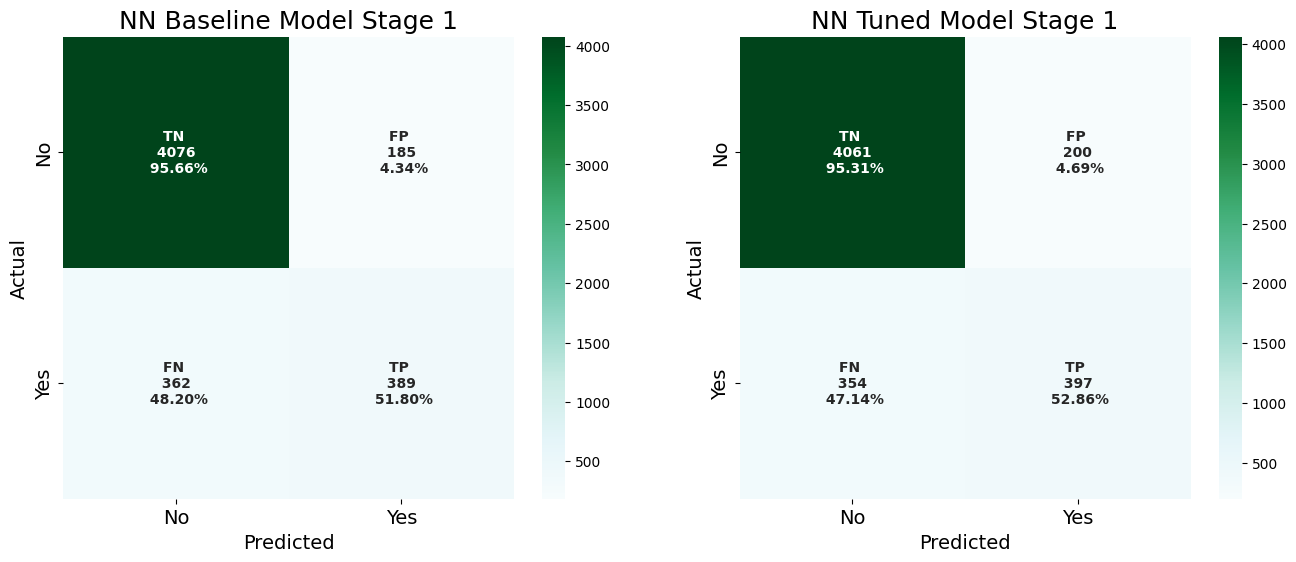

In [ ]:
# Display resulting confusion matrix
cm_labels_s1_HB= matrix_labels(cm_s1_HB)

fig, axes = plt.subplots(1, 2, figsize=(16,6))

sns.heatmap(cm_s1_NN_base, annot=cm_labels_s1_NN_base,annot_kws={"fontweight":'bold'}, fmt='', cmap='BuGn',ax=axes[0])
sns.heatmap(cm_s1_HB, annot=cm_labels_s1_HB, annot_kws={"fontweight":'bold'}, fmt='', cmap='BuGn',ax=axes[1])


for i in range(2):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)
axes[0].set_title('NN Baseline Model Stage 1',fontsize=18)
axes[1].set_title('NN Tuned Model Stage 1',fontsize=18)


While the training performance of the tuned model shows improvements, in terms of classification metrics it performs very similary to the baseline model. Further trials with extended hyperparameter searches and techniques as well as additional regularisation approaches such as dropout, lasso and ridge regularisation would be considered to attempt and improve the model performance if the model development was to be limited to the Stage 1 dataset.

# Stage 2 data

In [ ]:
# File URL
file_url2 = "Redacted_2"

**Stage 2: Pre-processing instructions**

- Remove any columns not useful in the analysis.
- Remove columns with categorical features with high cardinality (use >200 unique values, as a guideline for this data set).
- Remove columns with >50% data missing.
- Perform ordinal encoding for ordinal data.
- Perform one-hot encoding for all other categorical data.
- Choose how to engage with missing values, which can be done in one of two ways for this project:
  *   Impute the rows with appropriate values.
  *   Remove rows with missing values but ONLY in cases where rows with missing values are minimal: <2% of the overall data.



## Pre-Processing the Stage 2 Dataset

### 2.1 A View and pre-assess the dataset for duplicates and missing values.

In [ ]:
data_stage2 = pd.read_csv(file_url2)
data_stage2.sample(5)

The second dataset is an updated version of the Stage1 dateset and includes further two features relating to student engagement. Both features are numerical and as can be seen below, contain missing values.

In [ ]:
print(data_stage2.shape)
data_stage2.info()

In [ ]:
# Check for duplicated rows
data_stage2[data_stage2.duplicated()]

Before proceeding with the data pre-processing stages, it is useful to preserve the original dataset:

In [ ]:
# Make a copy of the raw Stage2 dataset
data_stage2_raw=data_stage2.copy()

### 2.1 B Convert target variable stored under feature 'CompletedCourse' to binary and rename it to 'DropOut'

In [ ]:
# Rename CompletedCourse to DropOut
data_stage2.rename(columns={'CompletedCourse': 'DropOut'}, inplace=True)
# data_stage2.columns.tolist()

Use the following initialisation:
* CompletedCourse_Yes = DropOut_No : '0'
* CompletedCourse_No = DropOut_Yes: '1'

In [ ]:
# Map Yes and Nos to '0' and '1's
data_stage2['DropOut']=data_stage2['DropOut'].map({'Yes': float(0), 'No': float(1)})


### 2.1 C Convert date of birth to age next:

In [ ]:
# Use function convert_to_age
data_stage2['Age'] = data_stage2['DateofBirth'].apply(convert_to_age)

### 2.1 D Define a function to perform all preliminary data removal steps.

In [ ]:
# Nested function to perform several data pre-processing steps
def feature_removal(dataframe,features_to_remove,num_type):
  # Use function to remove features deemed unnecessary
  out_1= remove_unnecessary(dataframe,features_to_remove)
  # Use function to remove categorical features with high cardinality
  out_2=remove_high_cardinality(out_1,num_type)
  # Use function to remove features based on missing data percentage)
  out_3=remove_high_missing(out_2,num_type)
  return out_3


In [ ]:
data_stage2_1=feature_removal(data_stage2,['RedactedFeature'],["float64"])


In [ ]:
display(data_stage2_1)

In [ ]:
data_stage2_1.info()

### 2.1 E Treating missing values for the numerical columns.

In [ ]:
def impute_or_remove(dataframe,num_type):
  num_cols=dataframe.select_dtypes(include=["float64"]).columns.tolist()
  remove_list=[]
  impute_list=[]
  for col in num_cols:
    missing_data=dataframe[col].isnull().sum()
    #print(f"{col}: {missing_data} missing values")
    if (missing_data > 0) and  (missing_data < dataframe.shape[0]*0.02):
      remove_list.append(col)
    elif (missing_data > dataframe.shape[0]*0.02):
      impute_list.append(col)
  return remove_list, impute_list


In [ ]:
# First divide numerical columns based on a missing row threshold of 2%
remove_list, impute_list=impute_or_remove(data_stage2_1,"float64")
# Columns with a missing row count below 2% go to the remove list
print(f"Columns to be cleaned: {remove_list}")
# Columns with a missing row count above 2% go the impute list
print(f"Columns to be imputed:{impute_list}")

In [ ]:
data_stage2_1.dropna(subset=remove_list, inplace=True)
data_stage2_1.info()



### 2.1 F Perform encoding:

In [ ]:
# Nested function to perform encodig
def encoding(dataframe,num_type):
  # Use function to perform ordinal encoding on CourseLevel column
  out_1= ordinal_encode(dataframe, "CourseLevel")
  # Use function to perform one-hot encoding on remaning categorical variables
  out_2= one_hot_encode(out_1,num_type)
  return out_2


In [ ]:
# Perform encoding
data_stage2_2 = encoding(data_stage2_1,["float64"])

data_stage2_2.info()



### 2.1 G Visualise the target variable to observe the changes.


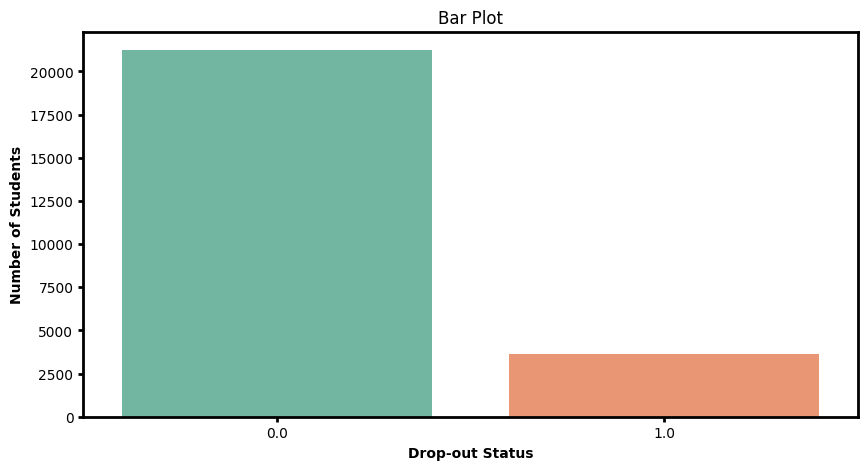

In [ ]:
plt.figure(figsize=(10, 5))
axes= sns.countplot(data=data_stage2_2, x='DropOut', hue='DropOut', palette='Set2',legend=False)
axes.tick_params(width=2)
for pos in ['top','bottom','left','right']:
    axes.spines[pos].set_linewidth(2)

plt.xlabel('Drop-out Status',fontweight='bold')
plt.ylabel('Number of Students',fontweight='bold')
plt.title('Bar Plot')
plt.show()


In [ ]:
# Compute the ratio
data_stage2_2.DropOut.value_counts(normalize=True)

,proportion
DropOut,
0.0,0.854774
1.0,0.145226


It can be inferred from the lack of change in the class ratios that the outcome variable, DropOut has not been altered.

## Pre-processing Variables for Model Training

### 2.2 A Perform the Train-Test Split

In [ ]:
# Target variable:
y_s2=data_stage2_2['DropOut']

# Input Features:
X_s2=data_stage2_2.drop(columns='DropOut')

In [ ]:
# Split the data into train, test and validation sets.
X_train_full_s2, X_test_s2, y_train_full_s2, y_test_s2 = train_test_split(X_s2, y_s2, stratify=y_s2, test_size=0.2, random_state=42)
X_train_s2, X_valid_s2, y_train_s2, y_valid_s2 = train_test_split(X_train_full_s2, y_train_full_s2, stratify=y_train_full_s2, test_size=0.1, random_state=42)

# Again, using stratify to ensure the training and testing sets have the same proportion of classes

### 2.2 B Perform scaling on the split datasets

As before, only the numerical variables are scaled following the train-test split.

In [ ]:
# Apply  Standard Scaler only on the numeric features that are not 0s and 1s (continuous)
col_list= ["RedactedFeatures"]
scaler = StandardScaler()
ct = ColumnTransformer([('num_preprocess', scaler, col_list)], remainder='passthrough')
X_train_scaled_s2= ct.fit_transform(X_train_s2)
X_valid_scaled_s2 = ct.transform(X_valid_s2)
X_test_scaled_s2= ct.transform(X_test_s2)

## XGBoost Classification for Stage 2

### 2.3 A Create and Train a Baseline XGBoost Model

For the baseline XGBoost model, the model tuned in Stage 1 can serve as a starting point where a direct comparison between the two datasets are still possible.

In [ ]:
# Create a XGBoost Model with an objective of binary classification
xgb_basemodel_s2 = XGBClassifier(
    objective='binary:logistic',
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
)

In [ ]:
# Train the XGBoost Model
xgb_basemodel_s2.fit(X_train_scaled_s2, y_train_s2)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=150,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# Make predictions
y_pred_s2_xgb_base = xgb_basemodel_s2.predict(X_test_scaled_s2)
# Evaluate the model
accuracy = accuracy_score(y_test_s2, y_pred_s2_xgb_base)
AUC = roc_auc_score(y_test_s2, y_pred_s2_xgb_base)

# Print the evaluation metrics.
print("Accuracy:", accuracy)
print("AUC:", AUC)

Accuracy: 0.9110842888754778
AUC: 0.7749591072104957


In [ ]:
# Full Classification Report
xgb_s2_base_report=classification_report(y_test_s2,y_pred_s2_xgb_base)
print(xgb_s2_base_report)

              precision    recall  f1-score   support

         0.0       0.93      0.97      0.95      4249
         1.0       0.75      0.58      0.66       722

    accuracy                           0.91      4971
   macro avg       0.84      0.77      0.80      4971
weighted avg       0.91      0.91      0.91      4971



The baseline XGBoost model achieves a high accuracy as well as a higher AUC score suggesting the classifications are not made at random. However, the AUC score should be considered alongside other metrics when there is a class imbalance. For instance, it can be seen that the TPR is better but still below 60%.

**Compare Classification Metrics: Stage1 vs Stage2**

In [ ]:
# Function to compare classification reports between Stages
def class_report_row(model,model_name,X_test,y_test):

  y_pred_model=model.predict(X_test)

  report = classification_report(y_test, y_pred_model, output_dict=True)
  ROC_AUC=roc_auc_score(y_test, y_pred_model)

  # Compute accuracy, precision, recall, F1 score, and ROC-AUC.
  row_dict={'Model':model_name,
            'Accuracy':report['accuracy'],
            'Precision':report['macro avg']['precision'],
            'Recall':report['macro avg']['recall'],'F1 Score':report['macro avg']['f1-score'],
            'ROC-AUC':ROC_AUC}

  # Output dictionary as a row
  return row_dict

In [ ]:
models=[xgb_bestmodel_grid_s1,xgb_basemodel_s2]
model_names=['Tuned XGBoost Model Stage 1','Baseline XGBoost Model Stage 2']
dict_row_s1=class_report_row(xgb_bestmodel_grid_s1,'Tuned XGBoost Model Stage 1',X_test_scaled_s1,y_test_s1)
dict_row_s2=class_report_row(xgb_basemodel_s2,'Baseline XGBoost Model Stage 2',X_test_scaled_s2,y_test_s2)

In [ ]:
pd.DataFrame.from_dict([dict_row_s1,dict_row_s2])

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned XGBoost Model Stage 1,0.894852,0.804072,0.754434,0.775698,0.754434
1,Baseline XGBoost Model Stage 2,0.911084,0.840420,0.774959,0.802356,0.774959


The addition of continuous numerical features relating to student engagement seems to have improved model performance at discriminating between two classes.

### 2.3 B Confusion Matrix and Analysis

In [ ]:
# Create confusion matrix
cm_s2_xgb_base= confusion_matrix(y_test_s2, y_pred_s2_xgb_base)


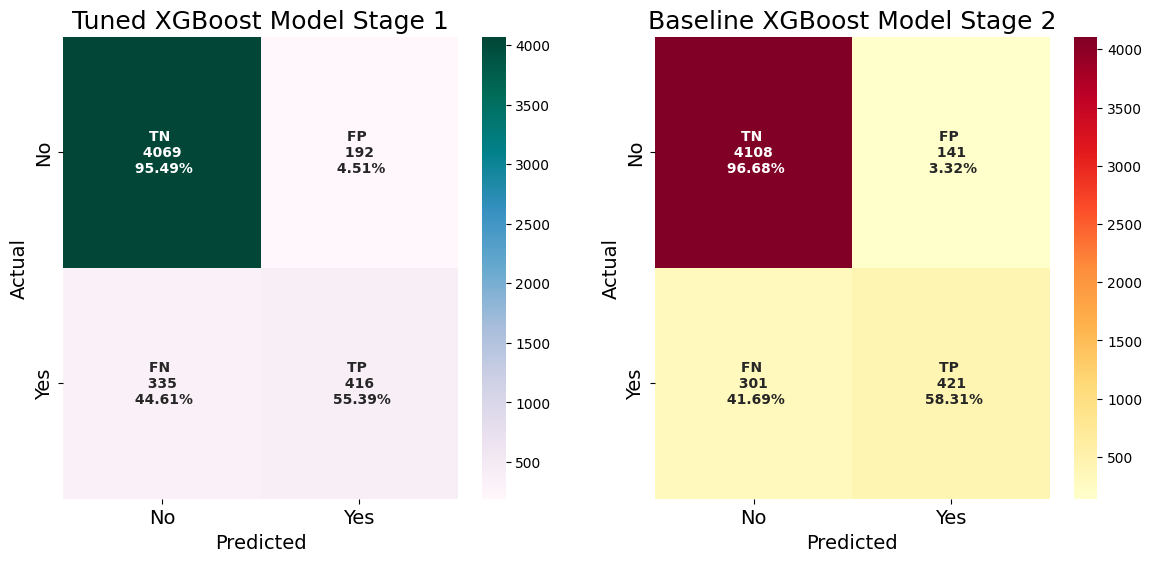

In [ ]:
# Display resulting confusion matrix
cm_labels_s2_xgb_base= matrix_labels(cm_s2_xgb_base)


fig, axes = plt.subplots(1, 2, figsize=(14,6))

sns.heatmap(cm_s1_xgb_grid, annot=cm_labels_s1_xgb_grid,annot_kws={"fontweight":'bold'}, fmt='', cmap='PuBuGn',ax=axes[0])
sns.heatmap(cm_s2_xgb_base, annot=cm_labels_s2_xgb_base,annot_kws={"fontweight":'bold'}, fmt='', cmap='YlOrRd',ax=axes[1])

for i in range(2):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)
axes[0].set_title('Tuned XGBoost Model Stage 1',fontsize=18)
axes[1].set_title('Baseline XGBoost Model Stage 2',fontsize=18)


The overall improvement in performance is also confirmed by the confusion matrix comparisons between the Stage 1 and Stage 2 classification metrics. As only the dataset has been updated and the preprocessing steps and XGBoost model kept identical between the two stages, the effect may be attributed to the addition of the two features relating to student engagement. An intuitive explanation would be that a record of absence is a strong predictor of dropout as those who regularly attend classes are more likely to succeed and may be able to do so due to the absence of a potential problem (health issues, financial trouble, etc).

### 2.3 C Tune the XGBoost Model

In [ ]:
# Hyperparameter search space for a Grid or Random search
xgb_grid_s2 = {"n_estimators":range(100,220,20),"max_depth":[5,7,10], "learning_rate":np.arange(0.05,0.35,0.05)}


The slightly updated search grid gives 6 x 3 x 6 = 108 hyperparamaters to tune which should be manageable with the grid search approach.

In [ ]:
# Tune using Grid Search with 10-fold cross-validation
xgb_grid_search_s2 = GridSearchCV(XGBClassifier(random_state=42), param_grid= xgb_grid_s2,cv=10,scoring='roc_auc',n_jobs=-1)
xgb_grid_search_s2.fit(X_train_scaled_s2, y_train_s2)



GridSearchCV(cv=10,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=No...
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': array([0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 ]),
                         'max_depth': [5, 7, 10],
                         'n_estimators': range(100, 220, 20)},
             scoring='roc_auc')

In [ ]:
# Print search results
best_xgb_grid_s2 = xgb_grid_search_s2.best_params_

print("Best Parameters:", best_xgb_grid_s2)
print("Best Score:", round(xgb_grid_search_s2.best_score_ , 3))

Best Parameters: {'learning_rate': np.float64(0.1), 'max_depth': 5, 'n_estimators': 200}
Best Score: 0.915


In [ ]:
# Build model with best parameters
xgb_bestmodel_grid_s2=xgb_grid_search_s2.best_estimator_


The grid search insists on a learning_rate of 0.1 and a max_depth of 5 while increasing the n_estimators from 150 to 200. The current configuration is now more aligned with the Bayesian optimisation results obtained in Stage 1.

### 2.3 D Evaluate the Tuned XGBoost Model and Compare Performance

In [ ]:
# Make predictions
y_pred_s2_xgb_grid = xgb_bestmodel_grid_s2.predict(X_test_scaled_s2)
# Evaluate the model
accuracy = accuracy_score(y_test_s2, y_pred_s2_xgb_grid)
AUC = roc_auc_score(y_test_s2, y_pred_s2_xgb_grid)

# Print the evaluation metrics.
print("Accuracy:", accuracy)
print("AUC:", AUC)

Accuracy: 0.9106819553409776
AUC: 0.7747237577164972


In [ ]:
models=[xgb_bestmodel_grid_s1,xgb_basemodel_s2,xgb_bestmodel_grid_s2]
model_names=['Grid Tuned XGBoost Model Stage 1','Baseline XGBoost Model Stage 2','Grid Tuned XGBoost Model Stage 2']
dict_row_s1=class_report_row(models[0],model_names[0],X_test_scaled_s1,y_test_s1)
dict_row_s2_1=class_report_row(models[1],model_names[1],X_test_scaled_s2,y_test_s2)
dict_row_s2_2=class_report_row(models[2],model_names[2],X_test_scaled_s2,y_test_s2)

The table below shows the evolution in performance starting from the tuned-model instantiated in Stage 1 which was then applied to the Stage 2 dataset and tuned using the grid search approach. While the model initially performed better on the Stage 2 dataset (as also indicated by the confusion matrix), the resulting classification metrics suggest there was no improvement in overall performance post-tuning.

In [ ]:
pd.DataFrame.from_dict([dict_row_s1,dict_row_s2_1,dict_row_s2_2])

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Grid Tuned XGBoost Model Stage 1,0.894852,0.804072,0.754434,0.775698,0.754434
1,Baseline XGBoost Model Stage 2,0.911084,0.840420,0.774959,0.802356,0.774959
2,Grid Tuned XGBoost Model Stage 2,0.910682,0.839077,0.774724,0.801725,0.774724


As the performance metrics did not improve, Bayesian optimisation will be implemented next both as a secondary attempt and a sanity check. As before, the cross-validation will be decreased by 2 fold to improve computation speed.

In [ ]:
#  Hyperparameter search space for the Bayesian search
xgb_grid2_s2={
    'n_estimators': Integer(100, 250, prior='uniform'),
    'max_depth': Integer(5, 10,prior='uniform'),
    'learning_rate': Real(0.1, 0.3,prior='log-uniform'),
}

In [ ]:
# create an instance of the Bayesian search object
xgb_bayes_search_s2 = BayesSearchCV(XGBClassifier(random_state=42), xgb_grid2_s2, cv=5, n_iter=120, random_state=42, scoring='roc_auc',n_jobs=-1)

# conduct randomized search over the parameter space
xgb_bayes_search_s2.fit(X_train_scaled_s2, y_train_s2)

BayesSearchCV(cv=5,
              estimator=XGBClassifier(base_score=None, booster=None,
                                      callbacks=None, colsample_bylevel=None,
                                      colsample_bynode=None,
                                      colsample_bytree=None, device=None,
                                      early_stopping_rounds=None,
                                      enable_categorical=False,
                                      eval_metric=None, feature_types=None,
                                      feature_weights=None, gamma=None,
                                      grow_policy=None, importance_type=None,
                                      interaction_constraints=No...
                                      multi_strategy=None, n_estimators=None,
                                      n_jobs=None, num_parallel_tree=None, ...),
              n_iter=120, n_jobs=-1, random_state=42, scoring='roc_auc',
              search_spaces={'learning_rate': Real(low=0.1, high=0.3, prior='log-uniform', transform='normalize'),
                             'max_depth': Integer(low=5, high=10, prior='uniform', transform='normalize'),
                             'n_estimators': Integer(low=100, high=250, prior='uniform', transform='normalize')})

In [ ]:
# Print search results
xgb_best_bayes_s2 = xgb_bayes_search_s2.best_params_

print("Best Parameters:", xgb_best_bayes_s2)
print("Best Score:", round(xgb_bayes_search_s2.best_score_ , 3))

Best Parameters: OrderedDict({'learning_rate': 0.14506724924692332, 'max_depth': 5, 'n_estimators': 169})
Best Score: 0.914


In [ ]:
# Build model with best parameters
xgb_bestmodel_bayes_s2=xgb_bayes_search_s2.best_estimator_


In [ ]:
models=[xgb_basemodel_s1,xgb_bestmodel_grid_s1,xgb_bestmodel_bayes_s1,
        xgb_basemodel_s2,xgb_bestmodel_grid_s2,xgb_bestmodel_bayes_s2]

model_names=['Baseline Model Stage 1','Grid Tuned Model Stage 1','Bayes Optimised Model Stage 1',
             'Baseline Model Stage 2','Grid Tuned Model Stage 2','Bayes Optimised Model Stage 2']

dict_row_s1_1=class_report_row(models[0],model_names[0],X_test_scaled_s1,y_test_s1)
dict_row_s1_2=class_report_row(models[1],model_names[1],X_test_scaled_s1,y_test_s1)
dict_row_s1_3=class_report_row(models[2],model_names[2],X_test_scaled_s1,y_test_s1)
dict_row_s2_1=class_report_row(models[3],model_names[3],X_test_scaled_s2,y_test_s2)
dict_row_s2_2=class_report_row(models[4],model_names[4],X_test_scaled_s2,y_test_s2)
dict_row_s2_3=class_report_row(models[5],model_names[5],X_test_scaled_s2,y_test_s2)

In [ ]:
pd.DataFrame.from_dict([dict_row_s1_1,dict_row_s1_2,dict_row_s1_3,dict_row_s2_1,dict_row_s2_2,dict_row_s2_3])

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline Model Stage 1,0.875499,0.819361,0.617460,0.652808,0.617460
1,Grid Tuned Model Stage 1,0.894852,0.804072,0.754434,0.775698,0.754434
2,Bayes Optimised Model Stage 1,0.894653,0.802700,0.756511,0.776518,0.756511
3,Baseline Model Stage 2,0.911084,0.840420,0.774959,0.802356,0.774959
4,Grid Tuned Model Stage 2,0.910682,0.839077,0.774724,0.801725,0.774724
5,Bayes Optimised Model Stage 2,0.909274,0.834131,0.774475,0.799790,0.774475


While the Bayesian optimisation returns a different set of hyperparameters (max_depth=5, learning_rate=0.145, n_estimators=169) compared to the grid search (max_depth=5, learning_rate=0.1, n_estimators=200) , the main change is in the n_estimators and this does not seem to improve the performance. So the tuned model acquired in Stage 1 remains the best XGBoost model (max_depth= 5, learning_rate=0.1, n_estimators=150). The results may be interpreted as a learning_rate of 0.1 and max_depth of 5 being the ideal parameters for the current classification problem with n_estimators allowed to vary between 150-200.  

### 2.3 E Feature Importance

Below is a the feature importance plot depicting the 20 features/attributes that are most strongly contributing towards the model's predictive power.

In [ ]:
# Create bar plot of top 20 features
feature_importance_s2 = pd.Series(xgb_bestmodel_grid_s2.feature_importances_, index=X_train_s2.columns).sort_values()

axes=feature_importance_s2.iloc[-20:].plot.barh()
axes.tick_params(width=2)

for pos in ['top','bottom','left','right']:
  axes.spines[pos].set_linewidth(2)


Moving from Stage 1 to Stage 2 the top 20 features which contribute most to  reducing the residual error (increasing gain) do change with several overlaps. Four of the top 5 features in Stage 1 remain in top 5 in Stage 2 and it can be seen that both features relating to engagement metrics are now listed in top 20, outperforming over 270 features in the dataset (post-encoding).

In [ ]:
for i in range(-5,0):
  feature=feature_importance_s2[feature_importance_s2==feature_importance_s2.iloc[i]].index[0]
  print(f"{feature}: {percentage_dropout(feature,data_stage2_2)}%")

Once again, while the feature importance list suggests these features contribute strongly to increasing the gain everytime a portion of data is split based on a threshold applied to them, their true effect on the outcome variable cannot be derived from the feature importance plot alone. And again, when the percentages of dropouts are checked for the top 5 features a variability is observed.

Use in stage 3: the coverage (portion of splits impacted) and weight(frequency of splits across the ensemble) are not taken into account within the same plot.

## Neural Network Implementation for Stage 2


### 2.4 A Create and Train the baseline NN model

Create the baseline model using the configuration returned by the Hyperband search performed for the Stage 1 dataset :

In [ ]:
# Use pre-defined function in Stage 1
NN_model_baseline_s2=baseline_model_s2(X_train_s2.shape[1])

In [ ]:
NN_model_baseline_s2.summary()

Model: "baseline_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 160)            │        62,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 128)            │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 48)             │         6,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_4 (Dense)                │ (None, 96)             │         4,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_5 (Dense)                │ (None, 240)            │        23,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_6 (Dense)                │ (None, 112)            │        26,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_7 (Dense)                │ (None, 112)            │        12,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           113 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 156,945 (613.07 KB)

 Trainable params: 156,945 (613.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train and visualise the learning performance.

history_baseline_s2 = NN_model_baseline_s2.fit(X_train_scaled_s2, y_train_s2, epochs=12, batch_size=32, validation_data=(X_valid_scaled_s2, y_valid_s2), verbose=0)


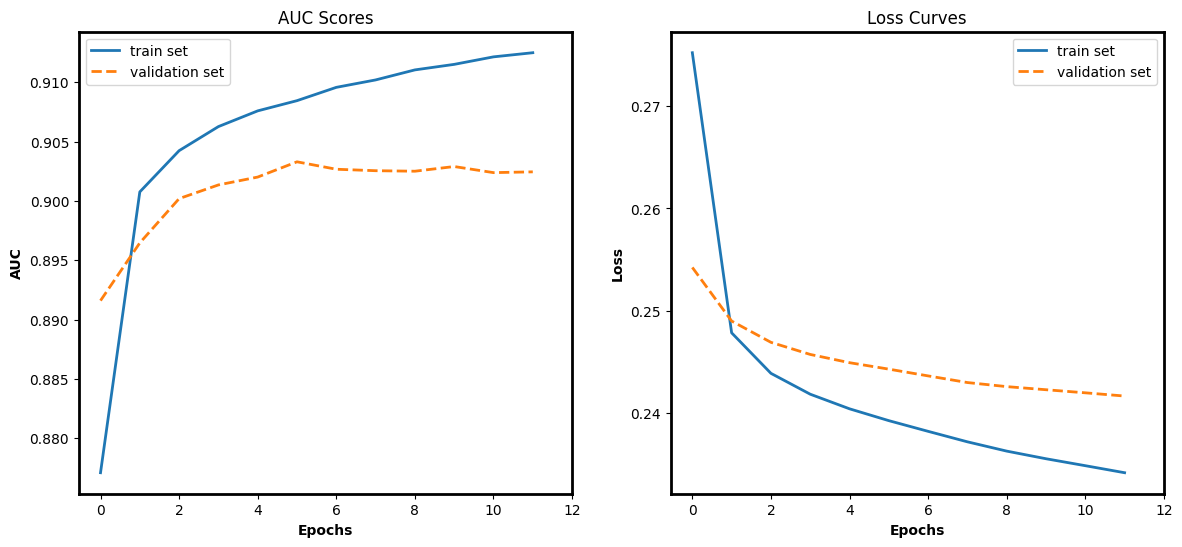

In [ ]:
# Visualise the loss and accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(14,6))
# Plot accuracy.
axes[0].plot(history_baseline_s2.history['AUC'],label='train set',linewidth=2)
axes[0].plot(history_baseline_s2.history['val_AUC'],linestyle='--',label='validation set',linewidth=2)
custom_ticks = list(range(0,14,2))
axes[0].xaxis.set_ticks(custom_ticks)
axes[0].set_title('AUC Scores')
axes[0].set_xlabel('Epochs',fontweight='bold')
axes[0].set_ylabel('AUC',fontweight='bold')
axes[0].legend()

# Plot loss.
axes[1].plot(history_baseline_s2.history['loss'],label='train set',linewidth=2)
axes[1].plot(history_baseline_s2.history['val_loss'],linestyle='--',label='validation set',linewidth=2)
axes[1].xaxis.set_ticks(custom_ticks)
axes[1].set_title('Loss Curves')
axes[1].set_xlabel('Epochs',fontweight='bold')
axes[1].set_ylabel('Loss',fontweight='bold')
axes[1].legend()

for i in range(2):
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)



The loss curves indicate the training set experiences a steep decline whereas the validation set starts from a lower value and experiences a smoother steady decline. The AUC scores show the validation set is slightly oscillating towards a higher value before saturing after 8-9 epochs. Notably, the validation curve starts at a higher value (compared to the training set) which can be attributed to the class imbalance. Even if there is no data leakage and stratification is implemented in the train-test split, the imbalance may be to large to overcome meaning the model can randomly guess a negative class as a non-dropout and frequently be correct even at the initial stages.

In [ ]:
# Evaluate the baseline model.
train_loss, train_accuracy = NN_model_baseline_s2.evaluate(X_train_scaled_s2, y_train_s2, verbose=0)
test_loss, test_accuracy = NN_model_baseline_s2.evaluate(X_test_scaled_s2, y_test_s2, verbose=0)

print('Train accuracy:',train_accuracy)
print('Test accuracy:',test_accuracy)
print('Train loss:', train_loss)
print('Test loss:', test_loss)



Train accuracy: 0.9166257381439209
Test accuracy: 0.8982464075088501
Train loss: 0.22993828356266022
Test loss: 0.24817606806755066


### 2.4 B Classification Metrics and Performance Analysis of the baseline model

In [ ]:
# Use the trained model to perform predictions on the X_test data set.
y_pred_s2= NN_model_baseline_s2.predict(X_test_scaled_s2)

156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
# Convert model prediction probabilties to binary
y_pred_s2_baseline= (y_pred_s2 > 0.5).astype('int')

In [ ]:
# Print the full set of evaluation metrics.

report_s2_baseline= classification_report(y_test_s2, y_pred_s2_baseline)
ROC_AUC=roc_auc_score(y_test_s2, y_pred_s2_baseline)

print(report_s2_baseline)
print("AUC:", ROC_AUC)

              precision    recall  f1-score   support

         0.0       0.92      0.97      0.95      4249
         1.0       0.74      0.53      0.62       722

    accuracy                           0.91      4971
   macro avg       0.83      0.75      0.78      4971
weighted avg       0.90      0.91      0.90      4971

AUC: 0.7501595617414297


While the accuracy (overall correct classifications) remain high due to the data imbalance, the recall on the positive class (TPR) remains around 53%.

In [ ]:
# Create confusion matrix
cm_s2_NN_base= confusion_matrix(y_test_s2, y_pred_s2_baseline)


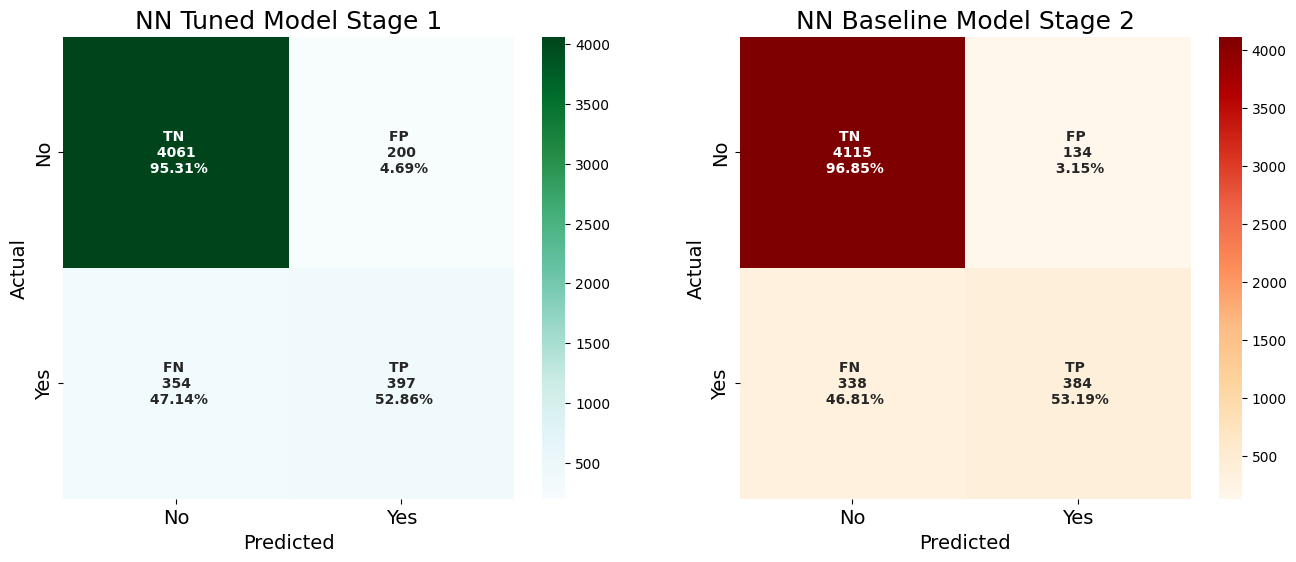

In [ ]:
# Display resulting confusion matrix
cm_labels_s2_NN_base= matrix_labels(cm_s2_NN_base)


fig, axes = plt.subplots(1, 2, figsize=(16,6))

sns.heatmap(cm_s1_HB, annot=cm_labels_s1_HB,annot_kws={"fontweight":'bold'},fmt='', cmap='BuGn',ax=axes[0])
sns.heatmap(cm_s2_NN_base, annot=cm_labels_s2_NN_base,annot_kws={"fontweight":'bold'},fmt='', cmap='OrRd',ax=axes[1])

for i in range(2):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)
axes[0].set_title('NN Tuned Model Stage 1',fontsize=18)
axes[1].set_title('NN Baseline Model Stage 2',fontsize=18)


The confusion matrix plots confirm the observartion that the recall on the postive class has not improved much at Stage 2 when using the tuned deep neural network model obtained in Stage 1.

### 2.4.C Tuning the Deep Neural Network Model

As before, the Hyperband approach will be implemented to tune the hyperparameters based on a search space. The previous tuning strategy has resulted in 7 Hidden layers which seemed to yield a well performing model on the Stage 1 dataset. However, the network architecture has become overly complicated, especially for the classification problem at hand. In this round, the same tuner will be used but with the max number of hidden layers reduced from 8 to 6 and the learning_rate=0.1 removed from the search space for increased speed.

In [ ]:
# Hyperparameter tuning using Keras tuner

def model_builder_s2(hp):
    # Initialize sequential API and start building model.
    model = Sequential(name='HB_model_2')
    # Add input layer
    model.add(Input(shape=(X_train_s2.shape[1],)))

    # Tune the number of hidden layers and units in each.

    # Number of hidden layers: 2-6 (total number of layers: 1-7)
    # Number of Units: 16 - 256 with stepsize of 16

    # Provide a choice of activation function:
    hp_activation = hp.Choice('activation', values=['relu', 'tanh'])

    for i in range(2,hp.Int("num_layers", 2, 7)):
        model.add(
                Dense(
                units=hp.Int("units_" + str(i), min_value=32, max_value=256, step=16),
                activation=hp_activation,name ="hidden_layer_"+ str(i-1))
            )
    # add name

    # Add output layer.
    model.add(Dense(units=1, activation="sigmoid"))

    # Provide a choice of optimizer
    hp_optimizer = hp.Choice("optimizer", values=['Adam', 'RMSprop'])

    # Tune learning rate for chosen optimizer with values from 0.01 to 0.0001
    hp_lr = hp.Float("learning_rate", min_value=0.0001, max_value=0.01, step=10, sampling="log")

    if hp_optimizer == 'RMSprop':
      optimizer = RMSprop(learning_rate=hp_lr)
    elif hp_optimizer == 'Adam':
      optimizer = Adam(learning_rate=hp_lr)

    # Define optimizer, loss, and metrics
    model.compile(optimizer=optimizer,
                  loss='binary_crossentropy',
                  metrics=["AUC"])

    # Return compiled model with hyperparameters to tune
    return model

In [ ]:
# Instantiate the hyperparameter tuner with the Hyperband approach
tuner_HB_s2 = kt.Hyperband(model_builder_s2,
                     objective=kt.Objective("val_AUC", direction="max"),
                     max_epochs=24, # set epochs relatively high for an extensive search
                     factor=3,
                     overwrite=True,
                     directory='dir',
                     project_name='hp_tuning',
                     seed=42,
                     )

In [ ]:
# Search space
tuner_HB_s2.search_space_summary()

Search space summary
Default search space size: 4
activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 2, 'max_value': 7, 'step': 1, 'sampling': 'linear'}
optimizer (Choice)
{'default': 'Adam', 'conditions': [], 'values': ['Adam', 'RMSprop'], 'ordered': False}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': 10, 'sampling': 'log'}


In [ ]:
# Add early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, verbose=0, mode='min', restore_best_weights=True)

In [ ]:
# Perform the search
tuner_HB_s2.search(X_train_scaled_s2, y_train_s2, epochs=24, batch_size=32, validation_data=(X_valid_scaled_s2, y_valid_s2), callbacks=[early_stopping])

Trial 30 Complete [00h 00m 46s]
val_AUC: 0.9077892303466797

Best val_AUC So Far: 0.9131730198860168
Total elapsed time: 00h 08m 00s


In [ ]:
# Get the best hyperparamter configuration
best_hps_HB_s2 = tuner_HB_s2.get_best_hyperparameters(num_trials=1)[0]

In [ ]:
# Output best hyperparameter values
best_hps_HB_s2.values

{'activation': 'relu',
 'num_layers': 7,
 'optimizer': 'RMSprop',
 'learning_rate': 0.0001,
 'units_2': 192,
 'units_3': 240,
 'units_4': 144,
 'units_5': 48,
 'tuner/epochs': 24,
 'tuner/initial_epoch': 8,
 'tuner/bracket': 2,
 'tuner/round': 2,
 'units_6': 32,
 'tuner/trial_id': '0012'}

Upon tuning with the Hyperband approach, the optimal configuration has been returned as 7 total layers with the 5 hidden layers having [192,240,144,48,32] neurons respectively. The activation function has been reverted back to ReLu while the optimiser has remained as RMSprop with a learning rate of 0.0001.

In [ ]:
model_HB_s2=tuner_HB_s2.hypermodel.build(best_hps_HB_s2)
model_HB_s2.summary()

Model: "HB_model_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 192)            │        74,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 240)            │        46,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_3 (Dense)          │ (None, 144)            │        34,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_4 (Dense)          │ (None, 48)             │         6,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_5 (Dense)          │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,465 (642.44 KB)

 Trainable params: 164,465 (642.44 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Define a function to create the baseline model
def baseline_model_s3(input_dim):

  model= Sequential([
          Input(shape=(input_dim,),name='input'),  # Input  layer
          layers.Dense(192, activation='relu',name='hidden_1'), # Hidden layer 1
          layers.Dense(240, activation='relu',name='hidden_2'), # Hidden layer 2
          layers.Dense(144, activation='relu',name='hidden_3'), # Hidden layer 3
          layers.Dense(48, activation='relu',name='hidden_4'),  # Hidden layer 4
          layers.Dense(32, activation='relu',name='hidden_5'),  # Hidden layer 5
          layers.Dense(1, activation='sigmoid',name='output')   # Output layer
                    ],name='baseline_model_s3')

  model.compile(optimizer=RMSprop(learning_rate=0.0001),
                  loss='binary_crossentropy',
                  metrics=['AUC'])

  return model

In [ ]:
model_HB_s2= baseline_model_s3(X_train_s2.shape[1])

In [ ]:
# Train and visualise the learning performance.

history_HB_s2 = model_HB_s2.fit(X_train_scaled_s2, y_train_s2, epochs=12, batch_size=32, validation_data=(X_valid_scaled_s2, y_valid_s2), verbose=0)



### 2.4.D Post-Tuning Performance and Analysis

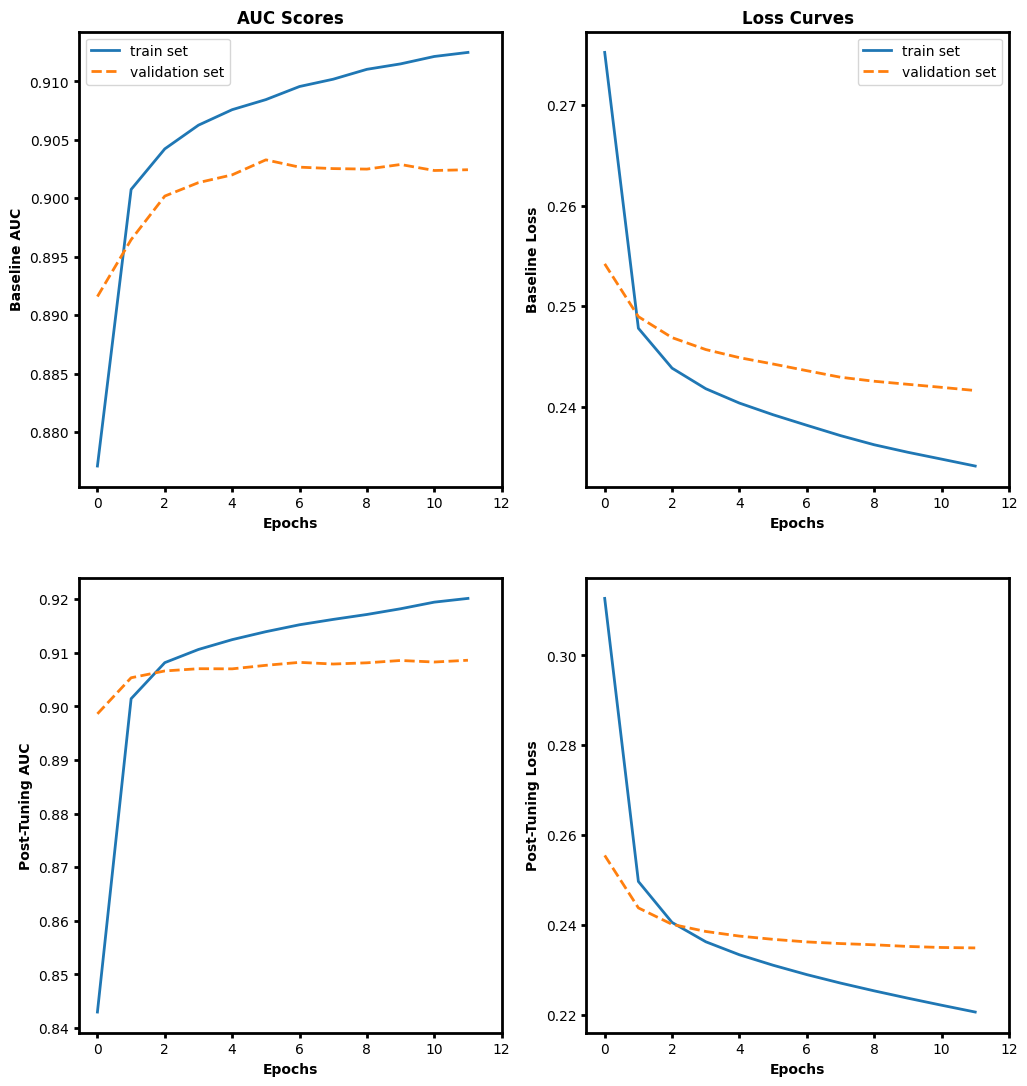

In [ ]:
# Visualise the loss and accuracy curves
fig, axes = plt.subplots(2, 2, figsize=(12,13))
axes.shape
# Plot accuracy.
axes[0,0].plot(history_baseline_s2.history['AUC'],label='train set',linewidth=2)
axes[0,0].plot(history_baseline_s2.history['val_AUC'],linestyle='--',label='validation set',linewidth=2)
custom_ticks = list(range(0,14,2))
axes[0,0].xaxis.set_ticks(custom_ticks)
axes[0,0].set_title('AUC Scores',fontweight='bold')
axes[0,0].set_xlabel('Epochs',fontweight='bold')
axes[0,0].set_ylabel('Baseline AUC',fontweight='bold')
axes[0,0].legend()

# Plot loss.
axes[0,1].plot(history_baseline_s2.history['loss'],label='train set',linewidth=2)
axes[0,1].plot(history_baseline_s2.history['val_loss'],linestyle='--',label='validation set',linewidth=2)
axes[0,1].xaxis.set_ticks(custom_ticks)
axes[0,1].set_title('Loss Curves',fontweight='bold')
axes[0,1].set_xlabel('Epochs',fontweight='bold')
axes[0,1].set_ylabel('Baseline Loss',fontweight='bold')
axes[0,1].legend()

# Plot accuracy.
axes[1,0].plot(history_HB_s2.history['AUC'],linewidth=2)
axes[1,0].plot(history_HB_s2.history['val_AUC'],linestyle='--',linewidth=2)
axes[1,0].xaxis.set_ticks(custom_ticks)
axes[1,0].set_xlabel('Epochs',fontweight='bold')
axes[1,0].set_ylabel('Post-Tuning AUC',fontweight='bold')

# Plot loss.
axes[1,1].plot(history_HB_s2.history['loss'],linewidth=2)
axes[1,1].plot(history_HB_s2.history['val_loss'],linestyle='--',linewidth=2)
axes[1,1].xaxis.set_ticks(custom_ticks)
axes[1,1].set_xlabel('Epochs',fontweight='bold')
axes[1,1].set_ylabel('Post-Tuning Loss',fontweight='bold')


for i, ax in enumerate(axes.flatten()):
  ax.tick_params(width=2)
  for pos in ['top','bottom','left','right']:
    ax.spines[pos].set_linewidth(2)

Continued improvement is observed where the validation is set shadowing the training set performance metrics with a slightly lower AUC score and a slightly higher loss. Once again, the class imbalance is evident, particularly in the AUC plot, where the validation curve starts from nearly 0.90 whereas the training set starts just above 0.84.

In [ ]:
# Use the trained model to perform predictions on the X_test data set.
y_pred_s2_HB= model_HB_s2.predict(X_test_scaled_s2)

156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


In [ ]:
# Convert model prediction probabilties to binary
y_pred_s2_HB= (y_pred_s2_HB > 0.5).astype('int')

# Print the full set of evaluation metrics.
report_s2_HB= classification_report(y_test_s2, y_pred_s2_HB)
ROC_AUC=roc_auc_score(y_test_s2, y_pred_s2_HB)

print(report_s2_HB)
print("AUC:", ROC_AUC)

              precision    recall  f1-score   support

         0.0       0.93      0.96      0.94      4249
         1.0       0.69      0.57      0.63       722

    accuracy                           0.90      4971
   macro avg       0.81      0.77      0.78      4971
weighted avg       0.89      0.90      0.90      4971

AUC: 0.7653909441947886


In [ ]:
# Create confusion matrix

cm_s2_HB= confusion_matrix(y_test_s2, y_pred_s2_HB)


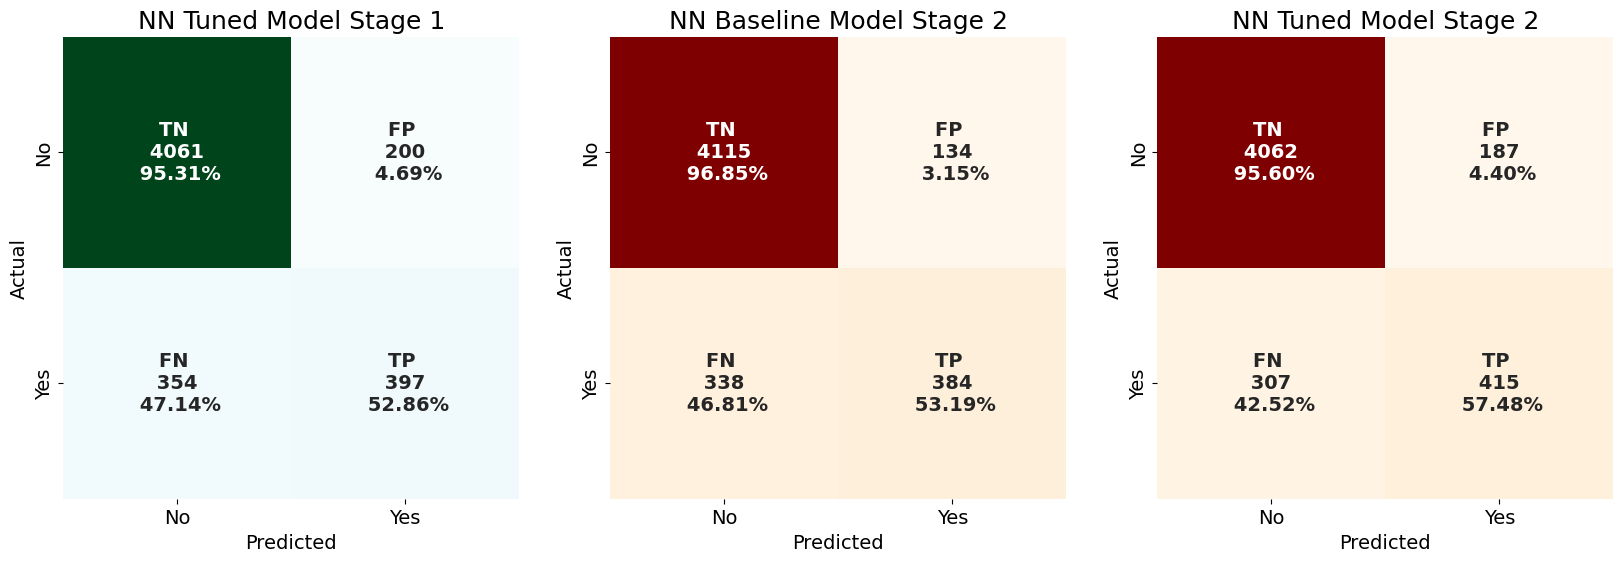

In [ ]:
# Display resulting confusion matrix
cm_labels_s2_HB= matrix_labels(cm_s2_HB)

fig, axes = plt.subplots(1, 3, figsize=(20,6))

sns.heatmap(cm_s1_HB, annot=cm_labels_s1_HB, annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='BuGn',ax=axes[0],cbar=False)
sns.heatmap(cm_s2_NN_base, annot=cm_labels_s2_NN_base,annot_kws={"fontsize":14,"fontweight":'bold'}, fmt='', cmap='OrRd',ax=axes[1],cbar=False)
sns.heatmap(cm_s2_HB, annot=cm_labels_s2_HB,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='OrRd',ax=axes[2],cbar=False)

for i in range(3):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)

axes[0].set_title('NN Tuned Model Stage 1',fontsize=18)
axes[1].set_title('NN Baseline Model Stage 2',fontsize=18)
axes[2].set_title('NN Tuned Model Stage 2',fontsize=18)




The confusion matrix plots suggest a notable improvement in the recall for the positive class (TPR) where further a trade-off between specificity (TNR) and sensitivity has occured (TPR), suggesting hyperparameter tuning has improved the model performance and simplifying the model architecture was the correct strategy.

# Stage 3 data

In [ ]:
# File URL
file_url3 = "Redacted_3"

**Stage 3: Pre-processing instructions**

- Remove any columns not useful in the analysis.
- Remove columns with categorical features with high cardinality (use >200 unique values, as a guideline for this data set).
- Remove columns with >50% data missing.
- Perform ordinal encoding for ordinal data.
- Perform one-hot encoding for all other categorical data.
- Choose how to engage with rows that have missing values, which can be done in one of two ways for this project:
  *   Impute the rows with appropriate values.
  *   Remove rows with missing values but ONLY in cases where rows with missing values are minimal: <2% of the overall data.






## Pre-Processing the Stage 3 Dataset

### 3.1 A View and pre-assess the dataset for duplicates and missing values.

In [ ]:
data_stage3 = pd.read_csv(file_url3)
data_stage3.sample(5)

The third dataset is an updated version of the Stage2 dateset and includes further three features relating to academic performance. All the additional features are numerical and as can be seen below, contain missing values:

In [ ]:
print(data_stage3.shape)
data_stage3.info()

In [ ]:
# Check for duplicated rows
data_stage3[data_stage3.duplicated()]

Before proceeding with the data pre-processing stages, it is useful to preserve the original dataset:

In [ ]:
# Make a copy of the original dataset
data_stage3_raw=data_stage3.copy()

### 3.1 B Convert target variable stored under feature 'CompletedCourse' to binary first, and rename it to 'DropOut'

In [ ]:
# Rename CompletedCourse to DropOut
data_stage3.rename(columns={'CompletedCourse': 'DropOut'}, inplace=True)

Use the following initialisation:
* CompletedCourse_Yes = DropOut_No : '0'
* CompletedCourse_No = DropOut_Yes: '1'

In [ ]:
# Map Yes and Nos to '0' and '1's
data_stage3['DropOut']=data_stage3['DropOut'].map({'Yes': float(0), 'No': float(1)})


### 3.1 C Convert date of birth to age nextt:

In [ ]:
# Use function convert_to_age
data_stage3['Age'] = data_stage3['DateofBirth'].apply(convert_to_age)

### 3.1 D Perform data removal on categorical variables as before.

In [ ]:
data_stage3_1=feature_removal(data_stage3,['RedactedFeature'],["float64"])

### 3.1 E Treating missing values for the numerical columns.

In [ ]:
# First divide numerical columns based on a missing row threshold of 2%
remove_list, impute_list=impute_or_remove(data_stage3_1,"float64")
# Columns with a missing row count below 2% go to the remove list
print(f"Columns to be cleaned: {remove_list}")
# Columns with a missing row count above 2% go the impute list
print(f"Columns to be imputed:{impute_list}")

In [ ]:
# Delete rows containing the missing values for features in the remove list:
data_stage3_1.dropna(subset=remove_list, inplace=True)
data_stage3_1.info()


**NOTE SEVERAL SECTIONS THAT RELATE TO THE IMPUTATION PROCESS HAVE BEEN REMOVED TO PRESERVE CONFIDENTIALITY**.

### 3.1 F Perform encoding:

In [ ]:
data_stage3_2=encoding(data_stage3_1,["float64"])
print(data_stage3_2.shape)

(24851, 393)


In [ ]:
data_stage3_2.info()

### 3.1 G Visualise the target variable to observe the changes.


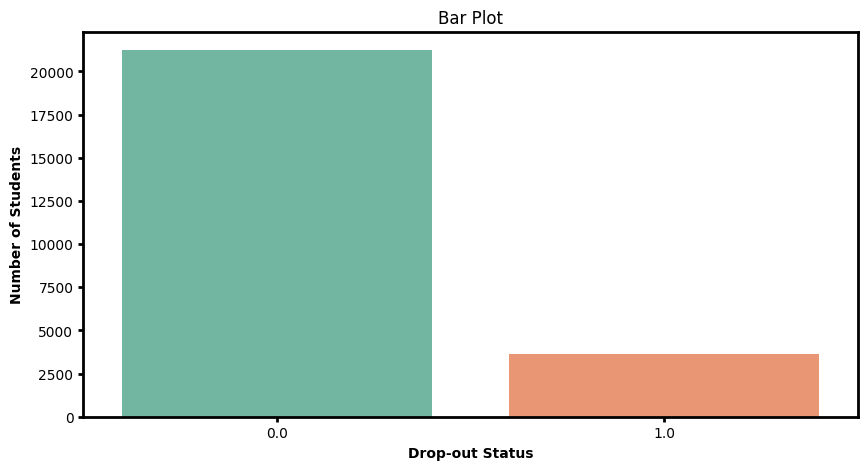

In [ ]:
plt.figure(figsize=(10, 5))
axes= sns.countplot(data=data_stage2_2, x='DropOut', hue='DropOut', palette='Set2',legend=False)
axes.tick_params(width=2)
for pos in ['top','bottom','left','right']:
    axes.spines[pos].set_linewidth(2)

plt.xlabel('Drop-out Status',fontweight='bold')
plt.ylabel('Number of Students',fontweight='bold')
plt.title('Bar Plot')
plt.show()


In [ ]:
# Compute the ratio
data_stage3_2.DropOut.value_counts(normalize=True)

,proportion
DropOut,
0.0,0.854774
1.0,0.145226


As expected, there are no significant changes in the target variable despite having a slightly different number of rows remaining relative to Stage 1 and Stage 2 datasets.

## Pre-processing Variables for Model Training

### 3.2 A Perform the Train-Test Split

In [ ]:
# Target variable:
y_s3=data_stage3_2['DropOut']

# Input Features:
X_s3=data_stage3_2.drop(columns='DropOut')

In [ ]:
# Split the data into train, test and validation sets.
X_train_full_s3, X_test_s3, y_train_full_s3, y_test_s3 = train_test_split(X_s3, y_s3, stratify=y_s3, test_size=0.2, random_state=42)
X_train_s3, X_valid_s3, y_train_s3, y_valid_s3 = train_test_split(X_train_full_s3, y_train_full_s3, stratify=y_train_full_s3, test_size=0.1, random_state=42)

# Again, using stratify to ensure the training and testing sets have the same proportion of classes

### 3.2 B Perform scaling on the split datasets

For the reasons presented in Stage 1, the standard scaling is performed only for the numerical features.

In [ ]:
# Apply  Standard Scaler only on the numeric features that are not 0s and 1s (continuous)
col_list= ["RedactedFeatures"]
scaler = StandardScaler()
ct = ColumnTransformer([('num_preprocess', scaler, col_list)], remainder='passthrough')
X_train_scaled_s3= ct.fit_transform(X_train_s3)
X_valid_scaled_s3 = ct.transform(X_valid_s3)
X_test_scaled_s3= ct.transform(X_test_s3)

## XGBoost Classification for Stage 3

### 3.3 A Create and Train a Baseline XGBoost Model

For the Stage 3 XGBoost model, the model tuned in Stage 1 which was selected to be the best XGBoost model in Stage 2 will serve as the starting point.

In [ ]:
# Create a XGBoost Model with an objective of binary classification
xgb_basemodel_s3 = XGBClassifier(
    objective='binary:logistic',
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
)

In [ ]:
# Train the XGBoost Model
xgb_basemodel_s3.fit(X_train_scaled_s3, y_train_s3)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=150,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# Make predictions
y_pred_s3_xgb_base = xgb_basemodel_s3.predict(X_test_scaled_s3)
# Evaluate the model
accuracy = accuracy_score(y_test_s3, y_pred_s3_xgb_base)
AUC = roc_auc_score(y_test_s3, y_pred_s3_xgb_base)

# Print the evaluation metrics.
print("Accuracy:", accuracy)
print("AUC:", AUC)

Accuracy: 0.9495071414202374
AUC: 0.8664165073222377


In [ ]:
# Full Classification Report
xgb_s3_base_report=classification_report(y_test_s3,y_pred_s3_xgb_base)
print(xgb_s3_base_report)

              precision    recall  f1-score   support

         0.0       0.96      0.98      0.97      4249
         1.0       0.89      0.75      0.81       722

    accuracy                           0.95      4971
   macro avg       0.92      0.87      0.89      4971
weighted avg       0.95      0.95      0.95      4971



**Compare Classification Metrics: Stage 2 vs Stage 3**

In [ ]:
models=[xgb_basemodel_s2,xgb_basemodel_s3]
model_names=['Best XGBoost Model Stage 2','Baseline XGBoost Model Stage 2']
dict_row_s2=class_report_row(xgb_basemodel_s2,'Best XGBoost Model Stage 2',X_test_scaled_s2,y_test_s2)
dict_row_s3=class_report_row(xgb_basemodel_s3,'Baseline XGBoost Model Stage 3',X_test_scaled_s3,y_test_s3)

In [ ]:
pd.DataFrame.from_dict([dict_row_s2,dict_row_s3])

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Best XGBoost Model Stage 2,0.911084,0.84042,0.774959,0.802356,0.774959
1,Baseline XGBoost Model Stage 3,0.949507,0.92196,0.866417,0.891274,0.866417


Based on the classification metrics presented in the table (and in the classification report above), the addition of new features relating to academic performance has lead to a significant improvement in the classification performance. This is especially true for the recall on the positive class which has reached 75%.

### 3.3 B Confusion Matrix and Analysis

In [ ]:
# Create confusion matrix
cm_s3_xgb_base= confusion_matrix(y_test_s3, y_pred_s3_xgb_base)


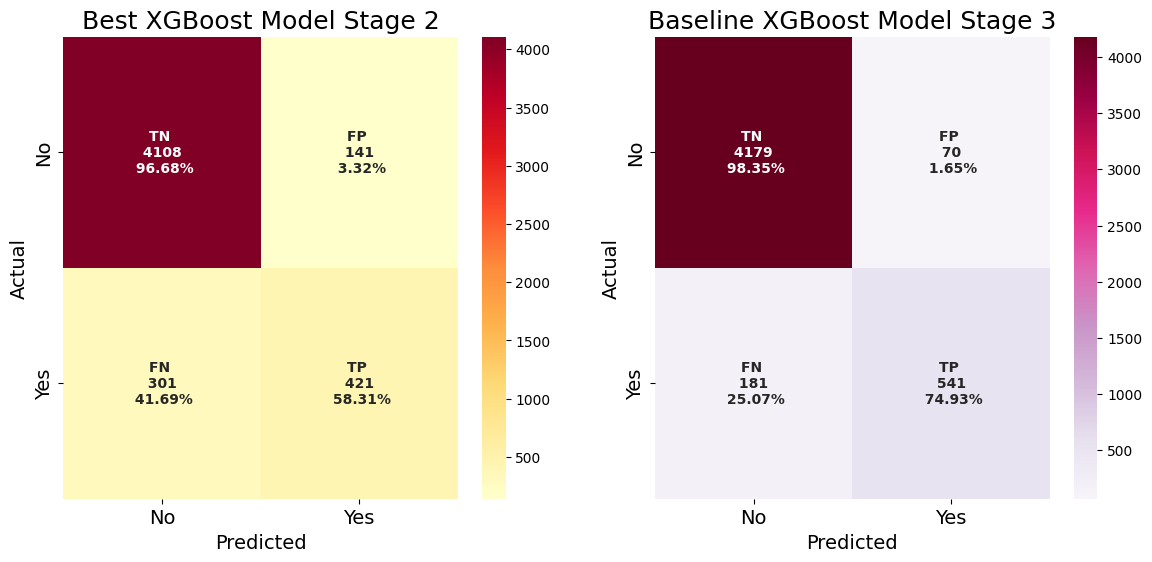

In [ ]:
# Display resulting confusion matrix
cm_labels_s3_xgb_base= matrix_labels(cm_s3_xgb_base)

fig, axes = plt.subplots(1, 2, figsize=(14,6))

sns.heatmap(cm_s2_xgb_base, annot=cm_labels_s2_xgb_base,annot_kws={"fontweight":'bold'}, fmt='', cmap='YlOrRd',ax=axes[0])
sns.heatmap(cm_s3_xgb_base, annot=cm_labels_s3_xgb_base,annot_kws={"fontweight":'bold'}, fmt='', cmap='PuRd',ax=axes[1])

for i in range(2):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)
axes[0].set_title('Best XGBoost Model Stage 2',fontsize=18)
axes[1].set_title('Baseline XGBoost Model Stage 3',fontsize=18)


The confusion matrix plots clearly highlight the improvement in classification performance of the baseline model which can be attributed to the addition of the student performance metrics (number of passed and failed modules out of total modules assessed). As these variables define the outcome, they may be expected to have strong impact on the model's classification performance/predictive power. Both the sensitivity (TPR) and the specificity (TNR) has increased with the largest improvement evident in the TPR.

### 3.3 C Tune the XGBoost Model

In [ ]:
# Hyperparameter search space for a Grid or Random search
xgb_grid_s3 = {"n_estimators":range(100,220,20),"max_depth":[4,5,6], "learning_rate":np.arange(0.05,0.35,0.05)}


The slightly updated search grid gives 6 x 3 x 6 = 108 hyperparamaters to tune which will still be manageable with the grid search approach.

In [ ]:
# Tune using Grid Search with 10-fold cross-validation
xgb_grid_search_s3 = GridSearchCV(XGBClassifier(random_state=42), param_grid= xgb_grid_s3,cv=10,scoring='roc_auc',n_jobs=-1)
xgb_grid_search_s3.fit(X_train_scaled_s3, y_train_s3)



GridSearchCV(cv=10,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=No...
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': array([0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 ]),
                         'max_depth': [4, 5, 6],
                         'n_estimators': range(100, 220, 20)},
             scoring='roc_auc')

In [ ]:
# Print search results
best_xgb_grid_s3 = xgb_grid_search_s3.best_params_

print("Best Parameters:", best_xgb_grid_s3)
print("Best Score:", round(xgb_grid_search_s3.best_score_ , 3))

Best Parameters: {'learning_rate': np.float64(0.25), 'max_depth': 6, 'n_estimators': 160}
Best Score: 0.967


This time, there is an increase in the optimal learning_rate and the max_depth parameters returned by the grid search. The learning rate has  increased 2.5 fold, the depth increased by only one level and the n_estimators slightly increased from 150 to 160.

In [ ]:
# Build model with best parameters
xgb_bestmodel_grid_s3=xgb_grid_search_s3.best_estimator_


### 3.3 D Evaluate the Tuned XGBoost Model and Compare Performance

In [ ]:
# Make predictions
y_pred_s3_xgb_grid = xgb_bestmodel_grid_s3.predict(X_test_scaled_s3)
# Evaluate the model
accuracy = accuracy_score(y_test_s3, y_pred_s3_xgb_grid)
AUC = roc_auc_score(y_test_s3, y_pred_s3_xgb_grid)

# Print the evaluation metrics.
print("Accuracy:", accuracy)
print("AUC:", AUC)

Accuracy: 0.9523234761617381
AUC: 0.8761117981809635


In [ ]:
models=[xgb_basemodel_s2,xgb_basemodel_s3,xgb_bestmodel_grid_s3]
model_names=['Best XGBoost Model Stage 2','Baseline XGBoost Model Stage 3','Grid Tuned XGBoost Model Stage 3']
dict_row_s2=class_report_row(models[0],model_names[0],X_test_scaled_s2,y_test_s2)
dict_row_s3_1=class_report_row(models[1],model_names[1],X_test_scaled_s3,y_test_s3)
dict_row_s3_2=class_report_row(models[2],model_names[2],X_test_scaled_s3,y_test_s3)

In [ ]:
pd.DataFrame.from_dict([dict_row_s2,dict_row_s3_1,dict_row_s3_2])

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Best XGBoost Model Stage 2,0.911084,0.840420,0.774959,0.802356,0.774959
1,Baseline XGBoost Model Stage 3,0.949507,0.921960,0.866417,0.891274,0.866417
2,Grid Tuned XGBoost Model Stage 3,0.952323,0.924787,0.876112,0.898240,0.876112


In Stage 3, consistent improvement has taken place with the tuned hyperparameters further improving the evaluation metrics of the XGBoost model. Thus, Bayesian optimisation can be skipped in this stage.

In [ ]:
# Create confusion matrix
cm_s3_xgb_grid= confusion_matrix(y_test_s3, y_pred_s3_xgb_grid)

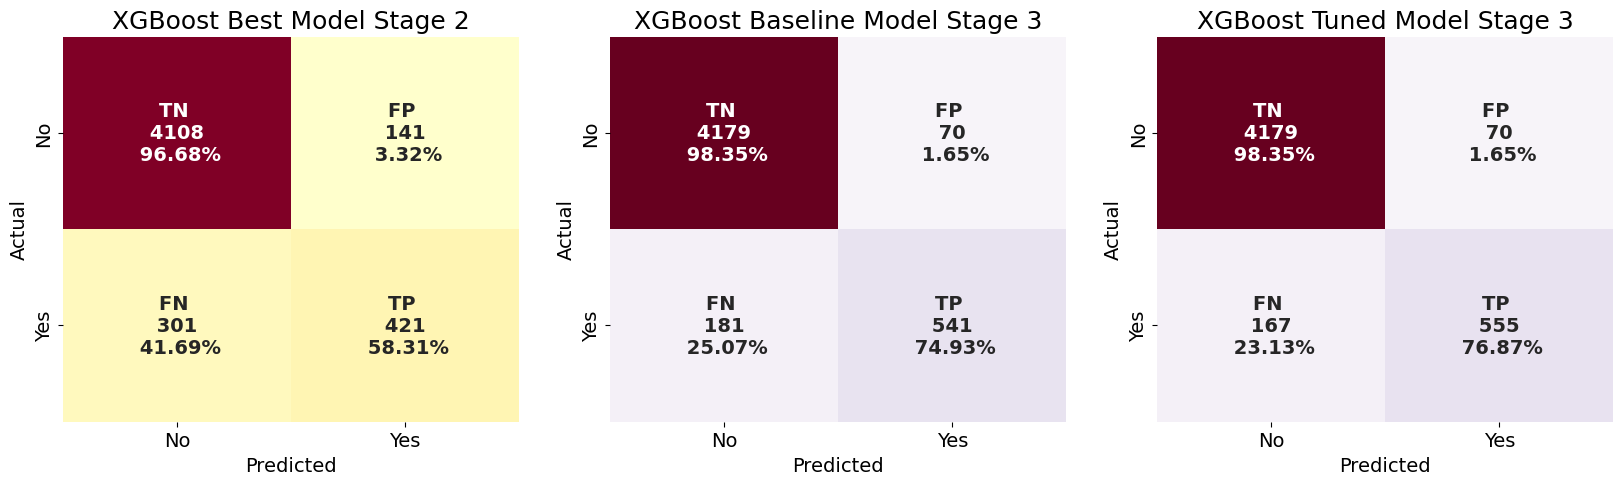

In [ ]:
# Display resulting confusion matrix
cm_labels_s3_xgb_grid= matrix_labels(cm_s3_xgb_grid)

fig, axes = plt.subplots(1, 3, figsize=(20,5))


sns.heatmap(cm_s2_xgb_base, annot=cm_labels_s2_xgb_base,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='YlOrRd',ax=axes[0],cbar=False)
sns.heatmap(cm_s3_xgb_base, annot=cm_labels_s3_xgb_base,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='PuRd',ax=axes[1],cbar=False)
sns.heatmap(cm_s3_xgb_grid, annot=cm_labels_s3_xgb_grid,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='PuRd',ax=axes[2],cbar=False)


for i in range(3):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)

axes[0].set_title('XGBoost Best Model Stage 2',fontsize=18)
axes[1].set_title('XGBoost Baseline Model Stage 3',fontsize=18)
axes[2].set_title('XGBoost Tuned Model Stage 3',fontsize=18)




The comparison of the confusion matrix plots highlight the slight increase in TPR moving from the baseline model to the tuned one in Stage 3 whereas a nearly 20 % improvement is achieved in the sensitivity relative to Stage 2.

### 3.3 E Feature Importance

Below is a the feature importance plot depicting the 20 features/attributes that are most strongly contributing towards the model's predictive power based on increase in gain.

In [ ]:
# Create bar plot of top 20 features
feature_importance_s3 = pd.Series(xgb_bestmodel_grid_s3.feature_importances_, index=X_train_s3.columns).sort_values()

axes=feature_importance_s3.iloc[-20:].plot.barh()
axes.tick_params(width=2)

for pos in ['top','bottom','left','right']:
  axes.spines[pos].set_linewidth(2)


Moving from Stage 2 to Stage 3, the features that yield the high-gain splits have once again changed with the engagement metrics ranking higher than before and one of the acedemic metrics added. Interestingly, three nationality-related consistently remain in top 4, but as argued before the observation cannot be explained simply by the relative dropout rate within these features (i.e.student groups).

In [ ]:
for i in range(-5,0):
  feature=feature_importance_s3[feature_importance_s3==feature_importance_s3.iloc[i]].index[0]
  print(f"{feature}: {percentage_dropout(feature,data_stage3_2)}%")

In the following segment, the inter-feature dropout rates will be studied:




In [ ]:
# Function to aggregate DropOut counts for the positive class
def dropout_per_feature(feature,dataset, threshold):

  feature_unstacked=dataset.groupby([feature,'DropOut']).size().unstack('DropOut')
  # Because size returns the total number of elements; upon grouping there may be NaN counts for a given class
  # feature_unstacked[np.isnan(feature_unstacked)] = 0 --> will ignore
  dropout_rate=round((feature_unstacked[1]/(feature_unstacked[1]+feature_unstacked[0]))*100,2)
  feature_rate=pd.DataFrame({feature:dropout_rate.index,'Dropout Rate':dropout_rate.values})
  return feature_rate[feature_rate['Dropout Rate'] >= threshold]


**NOTE THAT ONCE AGAIN SEVERAL SECTIONS REGARDING THE INTER-FEATURE ANALYSIS HAVE BEEN REMOVED TO PRESERVE CONFIDENTIALITY.**

## Neural Network Implementation for Stage 3


### 3.4 A Create and Train the baseline NN model

Create the baseline model using the hyperparameter configuration returned by the Hyperband search performed on the Stage 2 dataset :

In [ ]:
# Use pre-defined function in Stage 1
NN_model_baseline_s3=baseline_model_s3(X_train_s3.shape[1])

In [ ]:
NN_model_baseline_s3.summary()

Model: "baseline_model_s3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 192)            │        75,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 240)            │        46,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 144)            │        34,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_4 (Dense)                │ (None, 48)             │         6,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_5 (Dense)                │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165,041 (644.69 KB)

 Trainable params: 165,041 (644.69 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train and visualise the learning performance.

history_baseline_s3 = NN_model_baseline_s3.fit(X_train_scaled_s3, y_train_s3, epochs=12, batch_size=32, validation_data=(X_valid_scaled_s3, y_valid_s3), verbose=1)


Epoch 1/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - AUC: 0.8836 - loss: 0.2733 - val_AUC: 0.9333 - val_loss: 0.2062
Epoch 2/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.9387 - loss: 0.1951 - val_AUC: 0.9454 - val_loss: 0.1841
Epoch 3/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - AUC: 0.9472 - loss: 0.1782 - val_AUC: 0.9496 - val_loss: 0.1746
Epoch 4/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9521 - loss: 0.1685 - val_AUC: 0.9526 - val_loss: 0.1680
Epoch 5/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9553 - loss: 0.1614 - val_AUC: 0.9534 - val_loss: 0.1636
Epoch 6/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - AUC: 0.9581 - loss: 0.1555 - val_AUC: 0.9545 - val_loss: 0.1602
Epoch 7/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9606 - loss: 0.1506 - val_AUC: 0.9558 - val_loss: 0.1575
Epoch 8/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9618 - loss: 0.1463 - val_AUC: 0.9569 - val_loss: 0.1550
Epoch 9/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AU

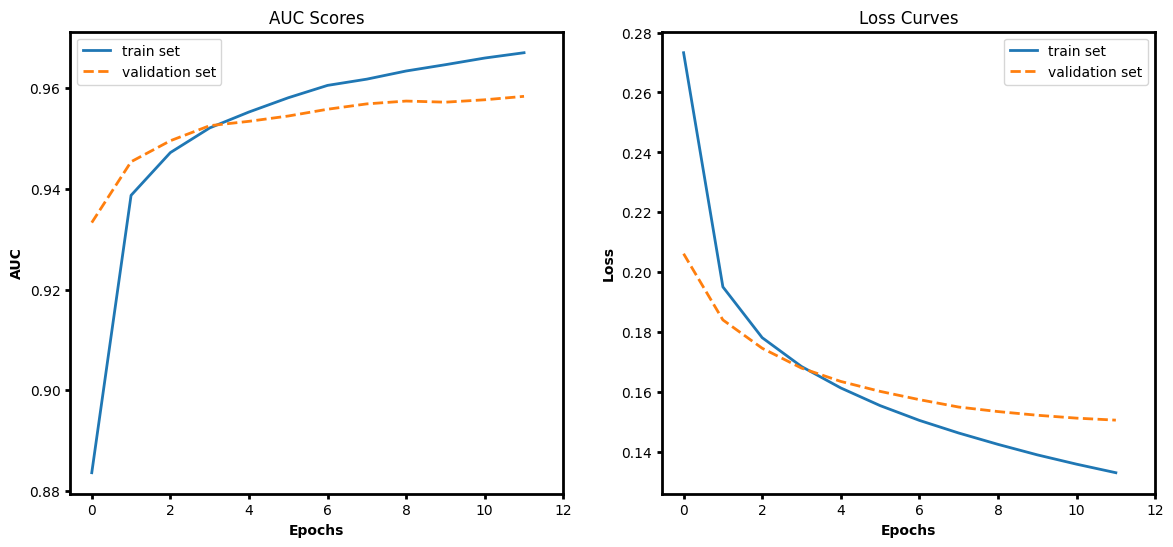

In [ ]:
# Visualise the loss and accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(14,6))
# Plot accuracy.
axes[0].plot(history_baseline_s3.history['AUC'],label='train set',linewidth=2)
axes[0].plot(history_baseline_s3.history['val_AUC'],linestyle='--',label='validation set',linewidth=2)
custom_ticks = list(range(0,14,2))
axes[0].xaxis.set_ticks(custom_ticks)
axes[0].set_title('AUC Scores')
axes[0].set_xlabel('Epochs',fontweight='bold')
axes[0].set_ylabel('AUC',fontweight='bold')
axes[0].legend()

# Plot loss.
axes[1].plot(history_baseline_s3.history['loss'],label='train set',linewidth=2)
axes[1].plot(history_baseline_s3.history['val_loss'],linestyle='--',label='validation set',linewidth=2)
axes[1].xaxis.set_ticks(custom_ticks)
axes[1].set_title('Loss Curves')
axes[1].set_xlabel('Epochs',fontweight='bold')
axes[1].set_ylabel('Loss',fontweight='bold')
axes[1].legend()

for i in range(2):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)


In [ ]:
# Evaluate the baseline model.
train_loss, train_accuracy = NN_model_baseline_s3.evaluate(X_train_scaled_s3, y_train_s3, verbose=0)
test_loss, test_accuracy = NN_model_baseline_s3.evaluate(X_test_scaled_s3, y_test_s3, verbose=0)

print('Train accuracy:',train_accuracy)
print('Test accuracy:',test_accuracy)
print('Train loss:', train_loss)
print('Test loss:', test_loss)



Train accuracy: 0.9709306359291077
Test accuracy: 0.9497864246368408
Train loss: 0.12731370329856873
Test loss: 0.1663752645254135


Once again, the AUC trends and the loss curves indicate a healthy pattern in terms of the model performance with the validation set shadowing the training set. The loss values are now lower whereas the AUC scores are higher reflecting an ideal scenario. The validation set still appears affected by the imbalance in class.

### 3.4 B Classification Metrics and Performance Analysis of the baseline model

In [ ]:
# Use the trained model to perform predictions on the X_test data set.
y_pred_s3= NN_model_baseline_s3.predict(X_test_scaled_s3)

156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [ ]:
# Convert model prediction probabilties to binary
y_pred_s3_baseline= (y_pred_s3 > 0.5).astype('int')

In [ ]:
# Print the full set of evaluation metrics.

report_s3_baseline= classification_report(y_test_s3, y_pred_s3_baseline)
ROC_AUC=roc_auc_score(y_test_s3, y_pred_s3_baseline)

print(report_s3_baseline)
print("AUC:", ROC_AUC)

              precision    recall  f1-score   support

         0.0       0.96      0.98      0.97      4249
         1.0       0.84      0.77      0.80       722

    accuracy                           0.95      4971
   macro avg       0.90      0.87      0.89      4971
weighted avg       0.94      0.95      0.94      4971

AUC: 0.871300661260365


In [ ]:
# Create confusion matrix
cm_s3_NN_base= confusion_matrix(y_test_s3, y_pred_s3_baseline)


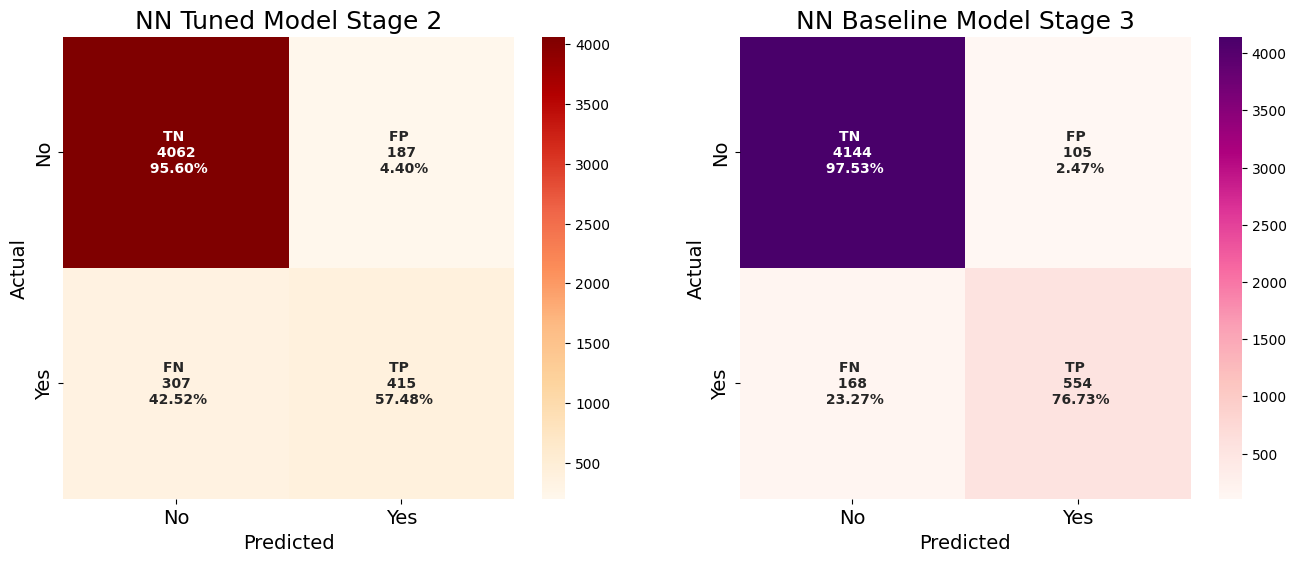

In [ ]:
# Display resulting confusion matrix
cm_labels_s3_NN_base= matrix_labels(cm_s3_NN_base)


fig, axes = plt.subplots(1, 2, figsize=(16,6))

sns.heatmap(cm_s1_HB, annot=cm_labels_s2_HB,annot_kws={"fontweight":'bold'},fmt='', cmap='OrRd',ax=axes[0])
sns.heatmap(cm_s3_NN_base, annot=cm_labels_s3_NN_base,annot_kws={"fontweight":'bold'},fmt='', cmap='RdPu',ax=axes[1])

for i in range(2):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)
axes[0].set_title('NN Tuned Model Stage 2',fontsize=18)
axes[1].set_title('NN Baseline Model Stage 3',fontsize=18)


Both the confusion matrix plots and the classification report suggest further improvement in model sensitivity with the TPR now reaching nearly 79%. The overall accuracy of the model has also improved. The effect can be attributed to the addition of the new features relating to academic performance as the same neural network model tuned in Stage 2 has been applied. Also, the effect is too large to be attributed to changes in hyperparameter values.

### 3.4.C Tuning the Deep Neural Network Model

Based on improvements achieved in Stage 2, the same hyperparameter search method is applied.

In [ ]:
# Hyperparameter tuning using Keras tuner

def model_builder_s3(hp):
    # Initialize sequential API and start building model.
    model = Sequential(name='HB_model_3')
    # Add input layer
    model.add(Input(shape=(X_train_s3.shape[1],)))

    # Tune the number of hidden layers and units in each.

    # Number of hidden layers: 2-6 (total number of layers: 1-7)
    # Number of Units: 16 - 256 with stepsize of 16

    # Provide a choice of activation function:
    hp_activation = hp.Choice('activation', values=['relu', 'tanh'])

    for i in range(2,hp.Int("num_layers", 2, 6)):
        model.add(
                Dense(
                units=hp.Int("units_" + str(i), min_value=32, max_value=256, step=16),
                activation=hp_activation,name ="hidden_layer_"+ str(i-1))
            )
    # add name

    # Add output layer.
    model.add(Dense(units=1, activation="sigmoid"))

    # Provide a choice of optimizer
    hp_optimizer = hp.Choice("optimizer", values=['Adam', 'RMSprop'])

    # Tune learning rate for chosen optimizer with values from 0.01 to 0.0001
    hp_lr = hp.Float("learning_rate", min_value=0.0001, max_value=0.01, step=10, sampling="log")

    if hp_optimizer == 'RMSprop':
      optimizer = RMSprop(learning_rate=hp_lr)
    elif hp_optimizer == 'Adam':
      optimizer = Adam(learning_rate=hp_lr)

    # Define optimizer, loss, and metrics
    model.compile(optimizer=optimizer,
                  loss='binary_crossentropy',
                  metrics=["AUC"])

    # Return compiled model with hyperparameters to tune
    return model

In [ ]:
# Instantiate the hyperparameter tuner with the Hyperband approach
tuner_HB_s3 = kt.Hyperband(model_builder_s3,
                     objective=kt.Objective("val_AUC", direction="max"),
                     max_epochs=24, # set epochs relatively high for an extensive search
                     factor=3,
                     overwrite=True,
                     directory='dir',
                     project_name='hp_tuning',
                     seed=42,
                     )

In [ ]:
# Search space
tuner_HB_s3.search_space_summary()

Search space summary
Default search space size: 4
activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 2, 'max_value': 6, 'step': 1, 'sampling': 'linear'}
optimizer (Choice)
{'default': 'Adam', 'conditions': [], 'values': ['Adam', 'RMSprop'], 'ordered': False}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': 10, 'sampling': 'log'}


In [ ]:
# Add early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, verbose=0, mode='min', restore_best_weights=True)

In [ ]:
# Perform the search
tuner_HB_s3.search(X_train_scaled_s3, y_train_s3, epochs=24, batch_size=32, validation_data=(X_valid_scaled_s3, y_valid_s3), callbacks=[early_stopping])

Trial 30 Complete [00h 00m 38s]
val_AUC: 0.9557687640190125

Best val_AUC So Far: 0.9640425443649292
Total elapsed time: 00h 09m 14s


In [ ]:
# Get the best hyperparamter configuration
best_hps_HB_s3 = tuner_HB_s3.get_best_hyperparameters(num_trials=1)[0]
best_hps_HB_s3.values

{'activation': 'relu',
 'num_layers': 4,
 'optimizer': 'RMSprop',
 'learning_rate': 0.001,
 'units_2': 144,
 'units_3': 128,
 'units_4': 48,
 'units_5': 48,
 'tuner/epochs': 24,
 'tuner/initial_epoch': 8,
 'tuner/bracket': 2,
 'tuner/round': 2,
 'tuner/trial_id': '0013'}

The Hyperband tuner predicts the optimal model to have 4 layers in total with only two hidden layers, the first with 144 and the second with 128 neurons. The number of hidden layers is halved, but the same activation and optimisation functions are used. This time the learning rate is increased to a default value of 0.001.

In [ ]:
model_HB_s3=tuner_HB_s3.hypermodel.build(best_hps_HB_s3)
model_HB_s3.summary()

Model: "HB_model_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 144)            │        56,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 128)            │        18,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,281 (294.07 KB)

 Trainable params: 75,281 (294.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Define a function to create the baseline model
def baseline_model_last(input_dim):

  model= Sequential([
          Input(shape=(input_dim,),name='input'),  # Input  layer
          layers.Dense(144, activation='relu',name='hidden_1'), # Hidden layer 1
          layers.Dense(128, activation='relu',name='hidden_2'), # Hidden layer 2
          layers.Dense(1, activation='sigmoid',name='output')   # Output layer
                    ],name='last_model')

  model.compile(optimizer=RMSprop(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['AUC'])

  return model

In [ ]:
# Instantiate the model
model_HB_s3=baseline_model_last(X_train_s3.shape[1])
# Train and visualise the learning performance.
history_HB_s3 = model_HB_s3.fit(X_train_scaled_s3, y_train_s3, epochs=12, batch_size=32, validation_data=(X_valid_scaled_s3, y_valid_s3), verbose=0)


### 3.4.D Post-Tuning Performance and Analysis

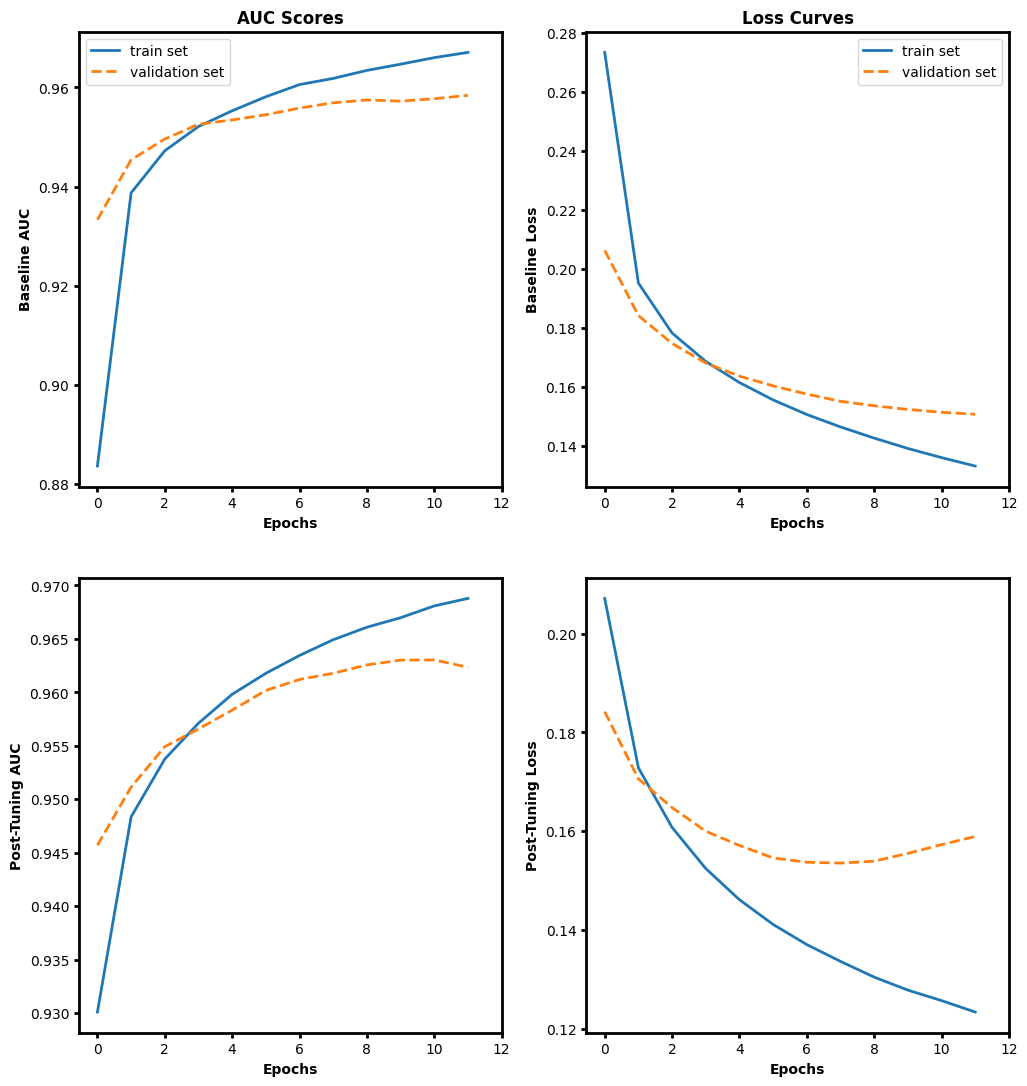

In [ ]:
# Visualise the loss and accuracy curves
fig, axes = plt.subplots(2, 2, figsize=(12,13))
axes.shape
# Plot accuracy.
axes[0,0].plot(history_baseline_s3.history['AUC'],label='train set',linewidth=2)
axes[0,0].plot(history_baseline_s3.history['val_AUC'],linestyle='--',label='validation set',linewidth=2)
custom_ticks = list(range(0,14,2))
axes[0,0].xaxis.set_ticks(custom_ticks)
axes[0,0].set_title('AUC Scores',fontweight='bold')
axes[0,0].set_xlabel('Epochs',fontweight='bold')
axes[0,0].set_ylabel('Baseline AUC',fontweight='bold')
axes[0,0].legend()

# Plot loss.
axes[0,1].plot(history_baseline_s3.history['loss'],label='train set',linewidth=2)
axes[0,1].plot(history_baseline_s3.history['val_loss'],linestyle='--',label='validation set',linewidth=2)
axes[0,1].xaxis.set_ticks(custom_ticks)
axes[0,1].set_title('Loss Curves',fontweight='bold')
axes[0,1].set_xlabel('Epochs',fontweight='bold')
axes[0,1].set_ylabel('Baseline Loss',fontweight='bold')
axes[0,1].legend()

# Plot accuracy.
axes[1,0].plot(history_HB_s3.history['AUC'],linewidth=2)
axes[1,0].plot(history_HB_s3.history['val_AUC'],linestyle='--',linewidth=2)
axes[1,0].xaxis.set_ticks(custom_ticks)
axes[1,0].set_xlabel('Epochs',fontweight='bold')
axes[1,0].set_ylabel('Post-Tuning AUC',fontweight='bold')

# Plot loss.
axes[1,1].plot(history_HB_s3.history['loss'],linewidth=2)
axes[1,1].plot(history_HB_s3.history['val_loss'],linestyle='--',linewidth=2)
axes[1,1].xaxis.set_ticks(custom_ticks)
axes[1,1].set_xlabel('Epochs',fontweight='bold')
axes[1,1].set_ylabel('Post-Tuning Loss',fontweight='bold')


for i, ax in enumerate(axes.flatten()):
  ax.tick_params(width=2)
  for pos in ['top','bottom','left','right']:
    ax.spines[pos].set_linewidth(2)


While the changes in the AUC and loss curve trends cannot be attributed to overfitting, after 8 epochs the validation set starts to diverge from the training set. Therefore, the model could benefit from further implementation of early stopping, after which further regularisation techniques could be used to experiment.

In [ ]:
# Use the trained model to perform predictions on the X_test data set.
y_pred_s3_HB= model_HB_s3.predict(X_test_scaled_s3)

156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [ ]:
# Convert model prediction probabilties to binary
y_pred_s3_HB= (y_pred_s3_HB > 0.5).astype('int')

# Print the full set of evaluation metrics.
report_s3_HB= classification_report(y_test_s3, y_pred_s3_HB)
ROC_AUC=roc_auc_score(y_test_s3, y_pred_s3_HB)

print(report_s3_HB)
print("AUC:", ROC_AUC)

              precision    recall  f1-score   support

         0.0       0.97      0.97      0.97      4249
         1.0       0.83      0.80      0.81       722

    accuracy                           0.95      4971
   macro avg       0.90      0.88      0.89      4971
weighted avg       0.95      0.95      0.95      4971

AUC: 0.8843138258374628


In [ ]:
# Create confusion matrix

cm_s3_HB= confusion_matrix(y_test_s3, y_pred_s3_HB)


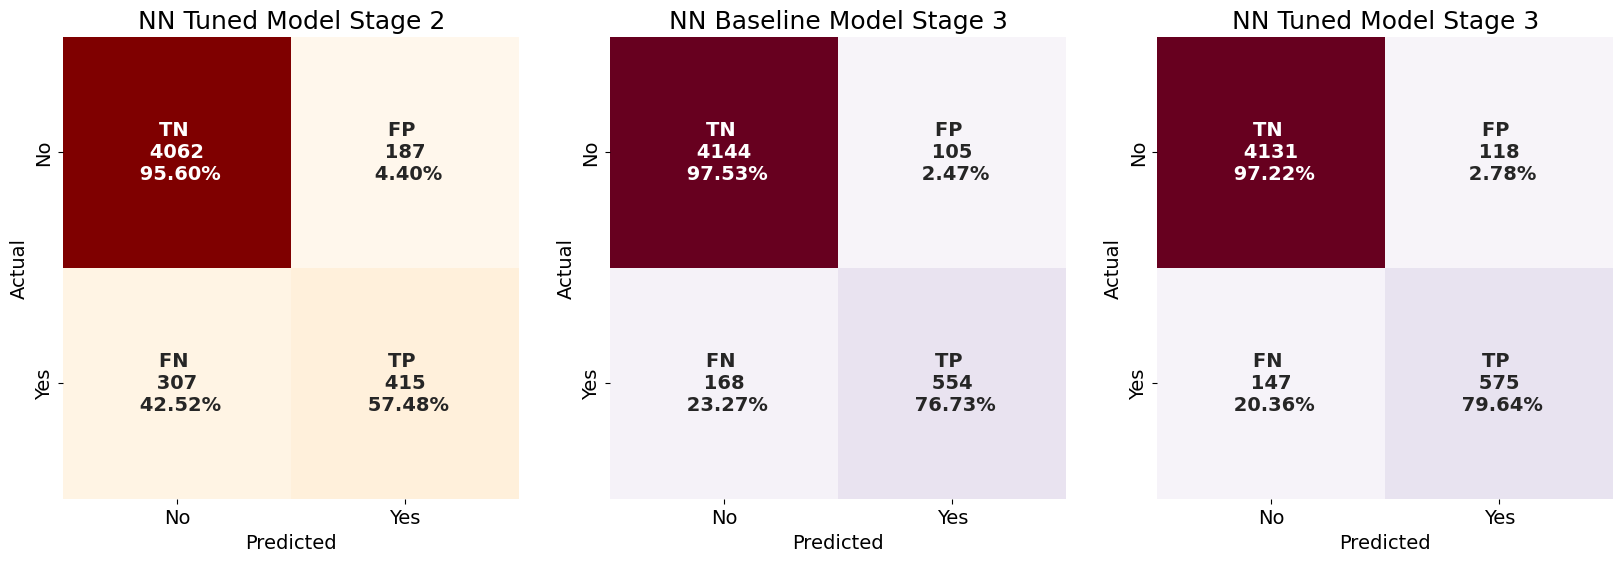

In [ ]:
# Display resulting confusion matrix
cm_labels_s3_HB= matrix_labels(cm_s3_HB)

fig, axes = plt.subplots(1, 3, figsize=(20,6))

sns.heatmap(cm_s2_HB, annot=cm_labels_s2_HB, annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='OrRd',ax=axes[0],cbar=False)
sns.heatmap(cm_s3_NN_base, annot=cm_labels_s3_NN_base,annot_kws={"fontsize":14,"fontweight":'bold'}, fmt='', cmap='PuRd',ax=axes[1],cbar=False)
sns.heatmap(cm_s3_HB, annot=cm_labels_s3_HB,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='PuRd',ax=axes[2],cbar=False)

for i in range(3):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)

axes[0].set_title('NN Tuned Model Stage 2',fontsize=18)
axes[1].set_title('NN Baseline Model Stage 3',fontsize=18)
axes[2].set_title('NN Tuned Model Stage 3',fontsize=18)




Despite the number of epochs not being optimal but kept the same for a more direct comparison, the tuned model achieves a relatively high sensitivity of nearly 80%.

### 3.4 E Implement Early-Stopping

In [ ]:
# Add early stopping callback
early_stopping_s3 = EarlyStopping(monitor='val_loss', patience=5, verbose=0, mode='min', restore_best_weights=True)

In [ ]:
# Retrain the model with Early Stopping callback
history_HB_s3_early = model_HB_s3.fit(X_train_scaled_s3, y_train_s3, epochs=12, batch_size=32, validation_data=(X_valid_scaled_s3, y_valid_s3), callbacks=[early_stopping_s3],verbose=1)

Epoch 1/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - AUC: 0.9757 - loss: 0.1064 - val_AUC: 0.9610 - val_loss: 0.1777
Epoch 2/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.9761 - loss: 0.1051 - val_AUC: 0.9608 - val_loss: 0.1807
Epoch 3/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - AUC: 0.9768 - loss: 0.1039 - val_AUC: 0.9609 - val_loss: 0.1854
Epoch 4/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - AUC: 0.9772 - loss: 0.1030 - val_AUC: 0.9617 - val_loss: 0.1879
Epoch 5/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - AUC: 0.9773 - loss: 0.1019 - val_AUC: 0.9587 - val_loss: 0.1893
Epoch 6/12
560/560 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - AUC: 0.9780 - loss: 0.1010 - val_AUC: 0.9616 - val_loss: 0.1917


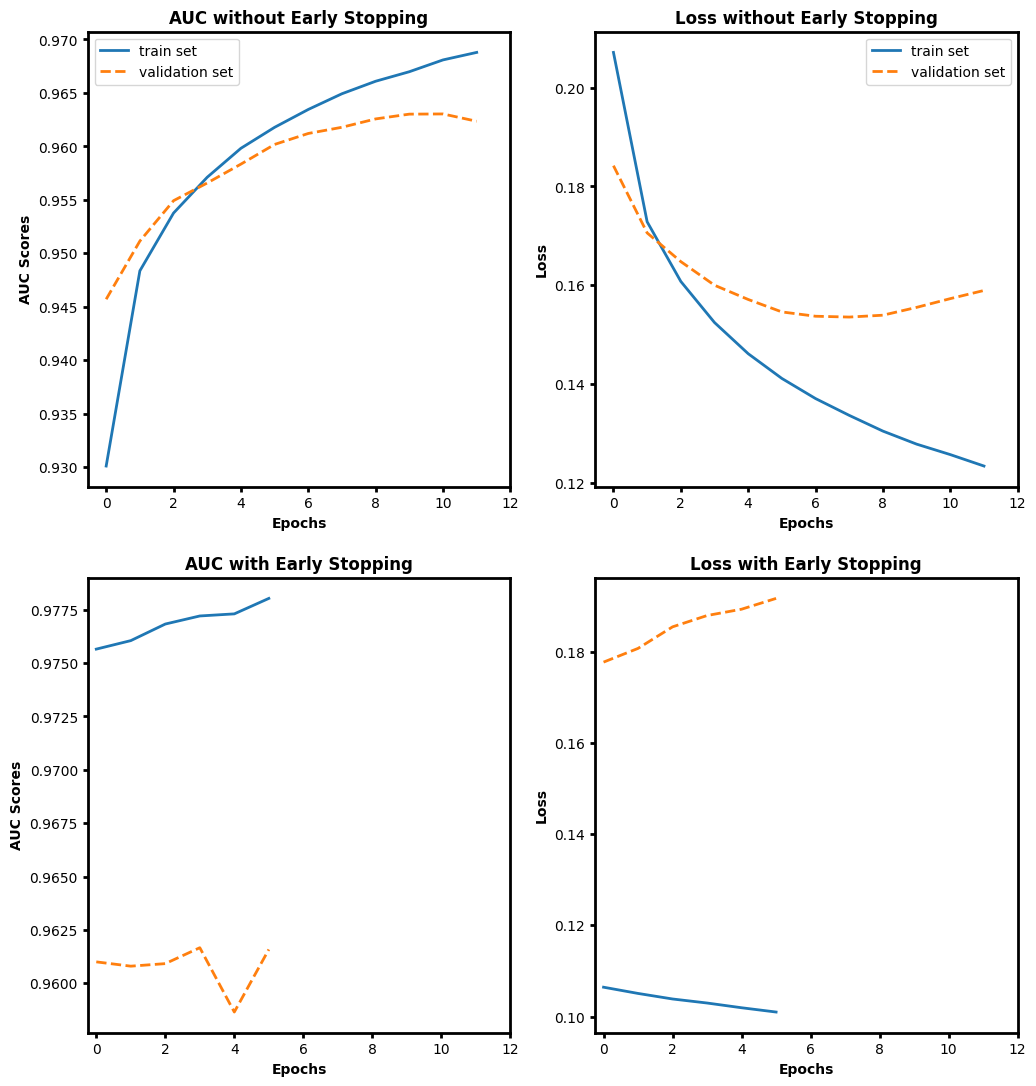

In [ ]:
# Visualise the loss and accuracy curves
fig, axes = plt.subplots(2, 2, figsize=(12,13))
axes.shape
# Plot accuracy.
axes[0,0].plot(history_HB_s3.history['AUC'],label='train set',linewidth=2)
axes[0,0].plot(history_HB_s3.history['val_AUC'],linestyle='--',label='validation set',linewidth=2)
custom_ticks = list(range(0,14,2))
axes[0,0].xaxis.set_ticks(custom_ticks)
axes[0,0].set_title('AUC without Early Stopping',fontweight='bold')
axes[0,0].set_xlabel('Epochs',fontweight='bold')
axes[0,0].set_ylabel('AUC Scores',fontweight='bold')
axes[0,0].legend()

# Plot loss.
axes[0,1].plot(history_HB_s3.history['loss'],label='train set',linewidth=2)
axes[0,1].plot(history_HB_s3.history['val_loss'],linestyle='--',label='validation set',linewidth=2)
axes[0,1].xaxis.set_ticks(custom_ticks)
axes[0,1].set_title('Loss without Early Stopping',fontweight='bold')
axes[0,1].set_xlabel('Epochs',fontweight='bold')
axes[0,1].set_ylabel('Loss',fontweight='bold')
axes[0,1].legend()

# Plot accuracy.
axes[1,0].plot(history_HB_s3_early.history['AUC'],linewidth=2)
axes[1,0].plot(history_HB_s3_early.history['val_AUC'],linestyle='--',linewidth=2)
axes[1,0].xaxis.set_ticks(custom_ticks)
axes[1,0].set_title('AUC with Early Stopping',fontweight='bold')
axes[1,0].set_xlabel('Epochs',fontweight='bold')
axes[1,0].set_ylabel('AUC Scores',fontweight='bold')

# Plot loss.
axes[1,1].plot(history_HB_s3_early.history['loss'],linewidth=2)
axes[1,1].plot(history_HB_s3_early.history['val_loss'],linestyle='--',linewidth=2)
axes[1,1].xaxis.set_ticks(custom_ticks)
axes[1,1].set_title('Loss with Early Stopping',fontweight='bold')
axes[1,1].set_xlabel('Epochs',fontweight='bold')
axes[1,1].set_ylabel('Loss',fontweight='bold')


for i, ax in enumerate(axes.flatten()):
  ax.tick_params(width=2)
  for pos in ['top','bottom','left','right']:
    ax.spines[pos].set_linewidth(2)


In [ ]:
# Use the trained model to perform predictions on the X_test data set.
y_pred_s3_HB_early= model_HB_s3.predict(X_test_scaled_s3)
# Convert model prediction probabilties to binary
y_pred_s3_HB_early= (y_pred_s3_HB_early > 0.5).astype('int')

156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [ ]:
# Create confusion matrix

cm_s3_HB_early= confusion_matrix(y_test_s3, y_pred_s3_HB_early)


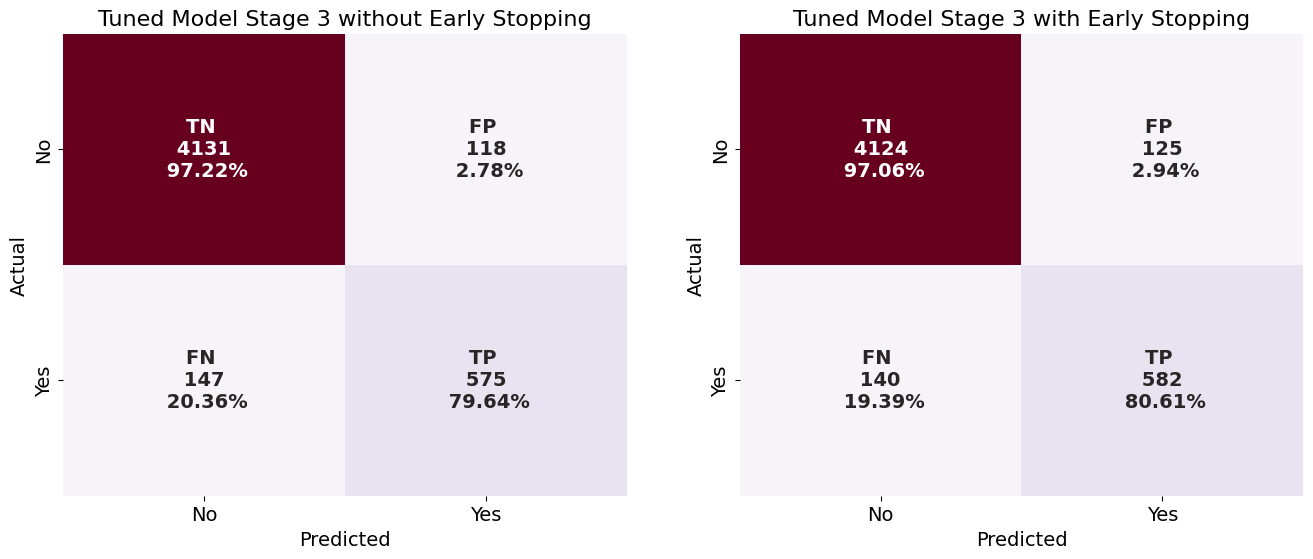

In [ ]:
# Display resulting confusion matrix
cm_labels_s3_HB_early= matrix_labels(cm_s3_HB_early)

fig, axes = plt.subplots(1, 2, figsize=(16,6))

sns.heatmap(cm_s3_HB, annot=cm_labels_s3_HB,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='PuRd',ax=axes[0],cbar=False)
sns.heatmap(cm_s3_HB_early, annot=cm_labels_s3_HB_early,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='PuRd',ax=axes[1],cbar=False)

for i in range(2):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)

axes[0].set_title('Tuned Model Stage 3 without Early Stopping',fontsize=16)
axes[1].set_title('Tuned Model Stage 3 with Early Stopping',fontsize=16)




# Conclusions

The plots below summarise the phased model development and changes in performance across different stages.

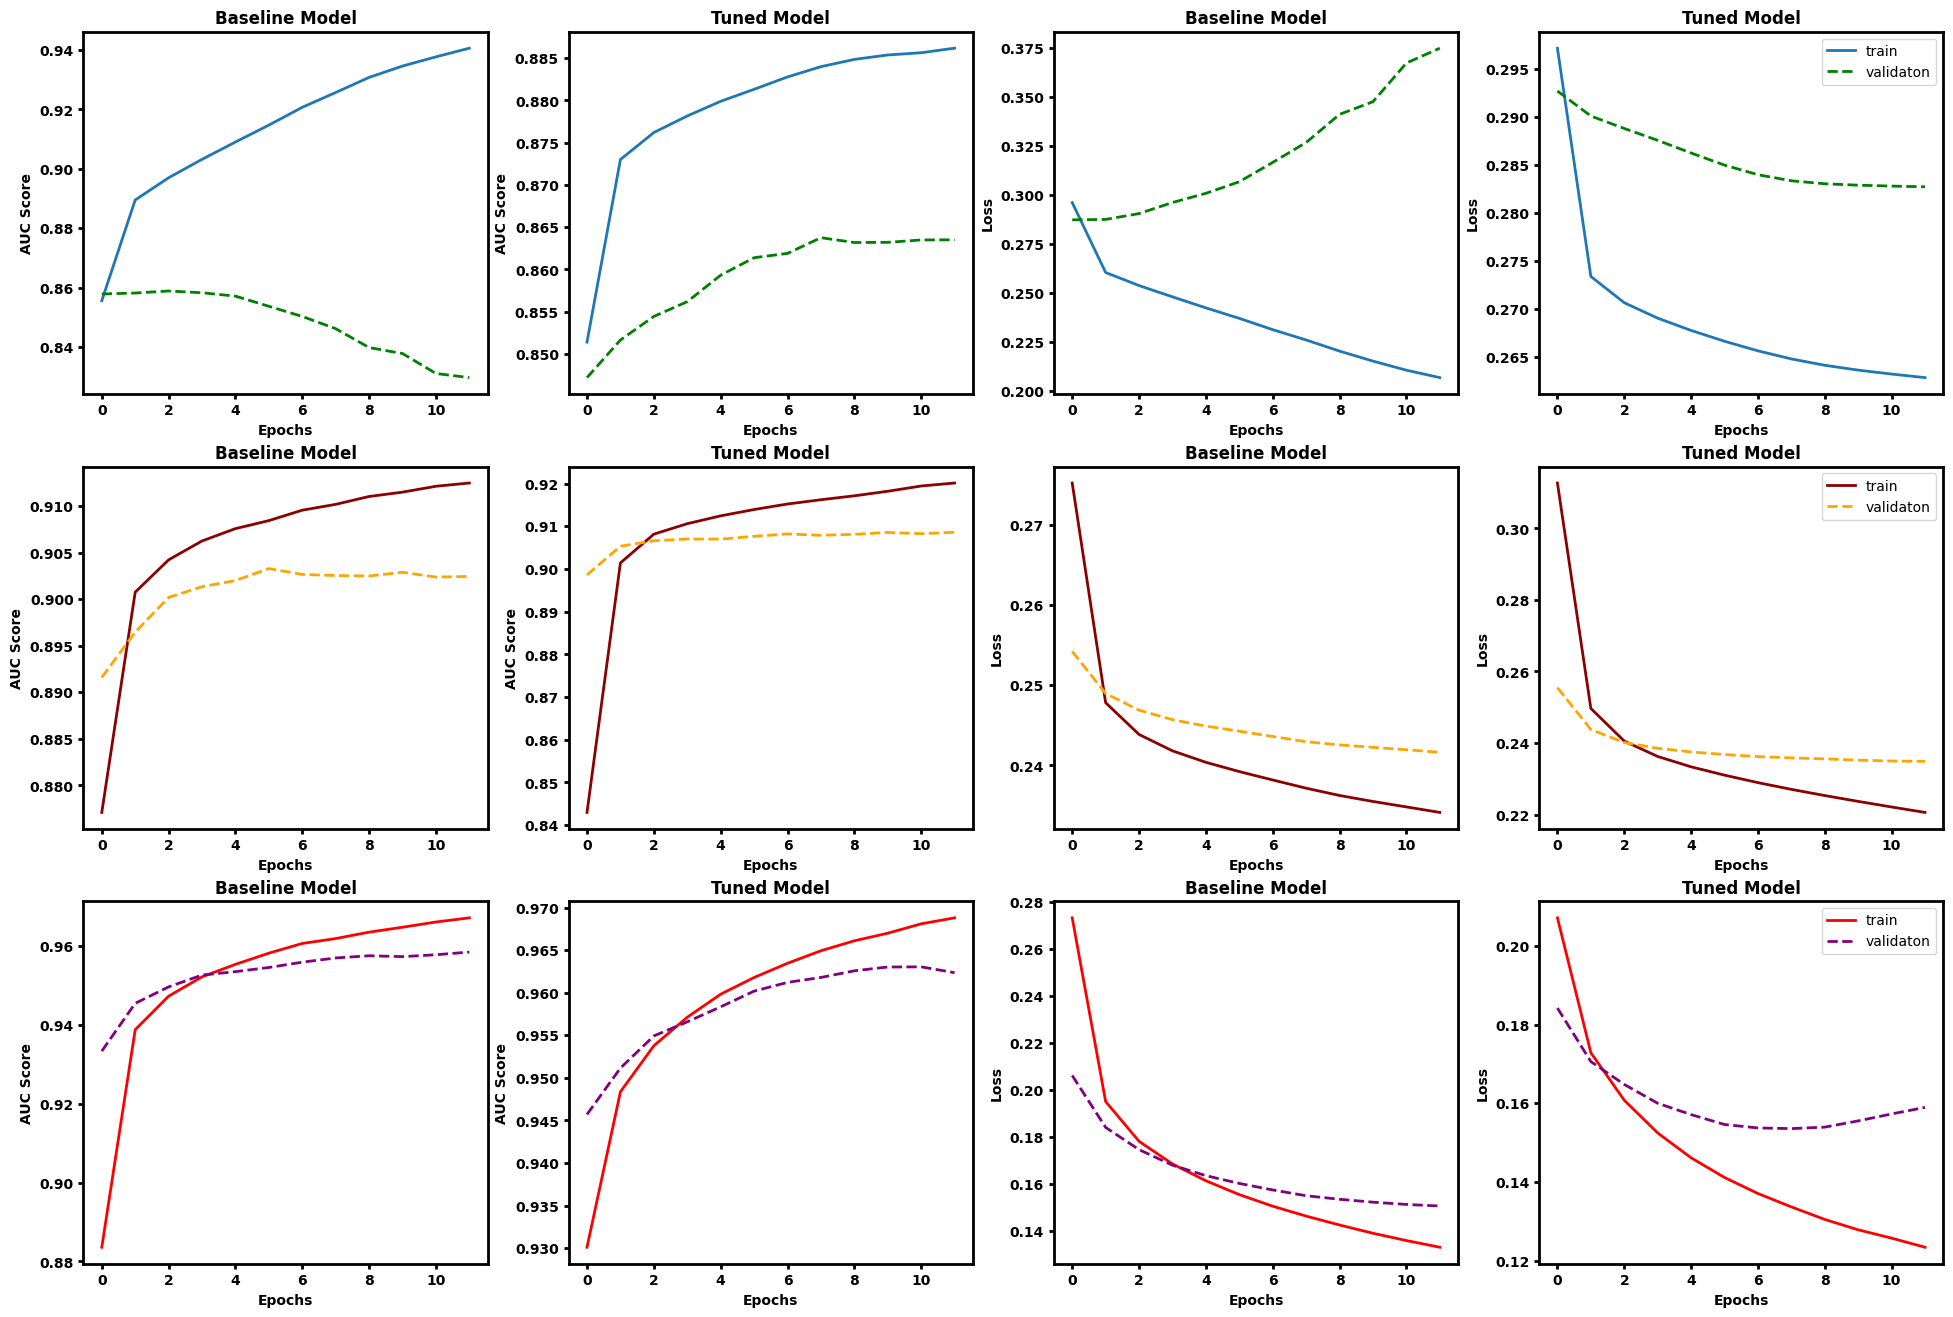

In [ ]:
# Collective loss and accuracy curves for all stages
fig, axes = plt.subplots(3, 4, figsize=(24,16))

# The Baseline vs Tuned Model for Stage 1
axes[0,0].plot(history_baseline_s1.history['AUC'],label='train',linewidth=2)
axes[0,0].plot(history_baseline_s1.history['val_AUC'],'g--',label='valid',linewidth=2)
axes[0,1].plot(history_HB_s1.history['AUC'],label='train',linewidth=2)
axes[0,1].plot(history_HB_s1.history['val_AUC'],'--g',label='valid',linewidth=2)
axes[0,2].plot(history_baseline_s1.history['loss'],linewidth=2)
axes[0,2].plot(history_baseline_s1.history['val_loss'],'--g',linewidth=2)
axes[0,3].plot(history_HB_s1.history['loss'],label='train',linewidth=2)
axes[0,3].plot(history_HB_s1.history['val_loss'],'--g',label='validaton',linewidth=2)


# The Baseline vs Tuned Model for Stage 2
axes[1,0].plot(history_baseline_s2.history['AUC'],color='darkred',label='train',linewidth=2)
axes[1,0].plot(history_baseline_s2.history['val_AUC'],'--', color='orange',label='valid',linewidth=2)
axes[1,1].plot(history_HB_s2.history['AUC'],color='darkred',label='train',linewidth=2)
axes[1,1].plot(history_HB_s2.history['val_AUC'],'--',color='orange',label='valid',linewidth=2)
axes[1,2].plot(history_baseline_s2.history['loss'],color='darkred',linewidth=2)
axes[1,2].plot(history_baseline_s2.history['val_loss'],'--',color='orange',linewidth=2)
axes[1,3].plot(history_HB_s2.history['loss'],color='darkred',label='train',linewidth=2)
axes[1,3].plot(history_HB_s2.history['val_loss'],'--', color='orange',label='validaton',linewidth=2)



# The Baseline vs Tuned Model for Stage 3
axes[2,0].plot(history_baseline_s3.history['AUC'],'-r',label='train',linewidth=2)
axes[2,0].plot(history_baseline_s3.history['val_AUC'],'--', color='purple',label='valid',linewidth=2)
axes[2,1].plot(history_HB_s3.history['AUC'],'-r',label='train',linewidth=2)
axes[2,1].plot(history_HB_s3.history['val_AUC'],'--',color='purple',label='valid',linewidth=2)
axes[2,2].plot(history_baseline_s3.history['loss'],'-r',linewidth=2)
axes[2,2].plot(history_baseline_s3.history['val_loss'],'--',color='purple',linewidth=2)
axes[2,3].plot(history_HB_s3.history['loss'],'-r',label='train',linewidth=2)
axes[2,3].plot(history_HB_s3.history['val_loss'],'--', color='purple',label='validaton',linewidth=2)

# Set legends
axes[0,3].legend()
axes[1,3].legend()
axes[2,3].legend()

# Set axis labels and titles

for i in range(3):
  for j in range(0,4,2):
    axes[i,j].set_title('Baseline Model',fontweight='bold')
  for k in range(1,5,2):
    axes[i,k].set_title('Tuned Model',fontweight='bold')
  for l in range(0,2,1):
    axes[i,l].set_ylabel('AUC Score',fontweight='bold')
  for m in range(2,4,1):
    axes[i,m].set_ylabel('Loss',fontweight='bold')

for i, ax in enumerate(axes.flatten()):
  ax.tick_params(width=2)
  ax.set_xlabel('Epochs',fontweight='bold')
  for tick in ax.get_xticklabels():
    tick.set_fontweight('bold')
  for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')
  for pos in ['top','bottom','left','right']:
    ax.spines[pos].set_linewidth(2)


The plot is organised as follows: The first two columns present the AUC-score plots whereas the next two columns present the loss curves. Each row is assigned to a different stage. As the titles suggest, a direct comparison of the plot type between baseline and tuned models is provided. Thus, starting from the first neural network created, the progression of improvement in model behaviour is highlighted.

The first baseline model shows clear signs of overfitting which upon hyperparameter tuning is overcome. Further improvement is achieved at every consequent stage and the ideal behaviour is preserved till the last model in stage 3. Without early stopping, the validation set starts slightly deviating from the training set towards high variance which means further regularisation is needed to help the model generalise better.

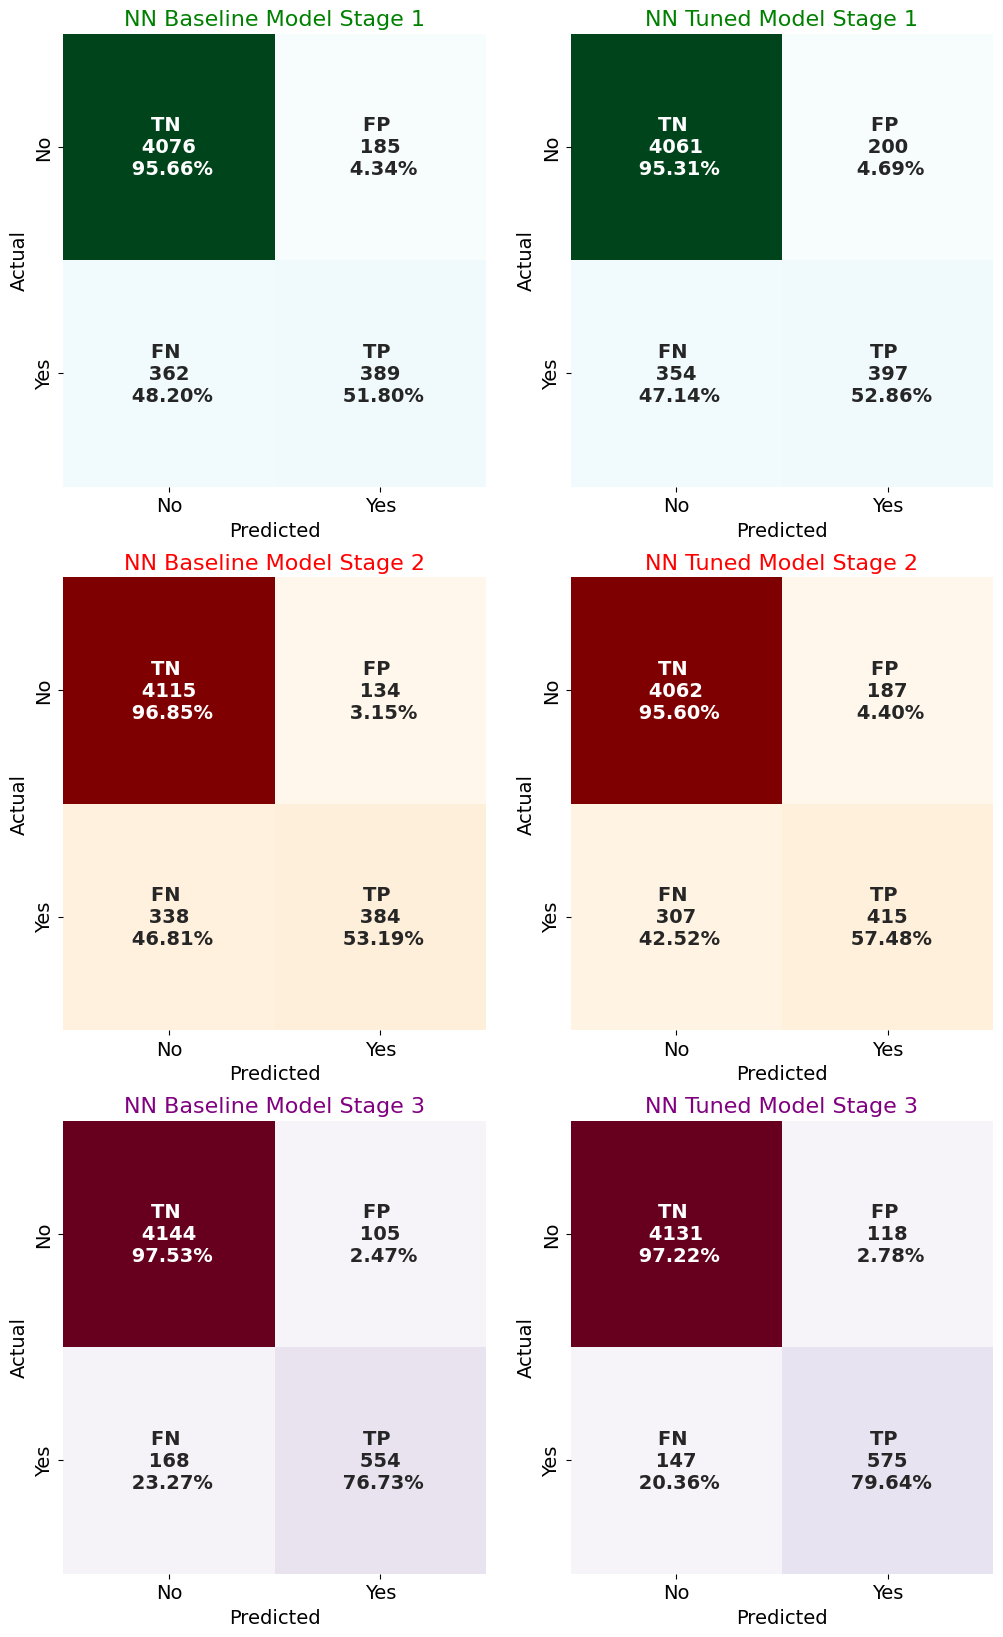

In [ ]:
# Confusion Matrix Comparisons for the NN Models

fig, axes = plt.subplots(3, 2, figsize=(12,20))
sns.heatmap(cm_s1_NN_base, annot=cm_labels_s1_NN_base, annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='BuGn',ax=axes[0,0],cbar=False)
sns.heatmap(cm_s1_HB, annot=cm_labels_s1_HB, annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='BuGn',ax=axes[0,1],cbar=False)
sns.heatmap(cm_s2_NN_base, annot=cm_labels_s2_NN_base, annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='OrRd',ax=axes[1,0],cbar=False)
sns.heatmap(cm_s2_HB, annot=cm_labels_s2_HB, annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='OrRd',ax=axes[1,1],cbar=False)
sns.heatmap(cm_s3_NN_base, annot=cm_labels_s3_NN_base,annot_kws={"fontsize":14,"fontweight":'bold'}, fmt='', cmap='PuRd',ax=axes[2,0],cbar=False)
sns.heatmap(cm_s3_HB, annot=cm_labels_s3_HB,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='PuRd',ax=axes[2,1],cbar=False)

for ax in axes.flatten():
  ax.xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  ax.yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  ax.set_xlabel('Predicted',fontsize=14)
  ax.set_ylabel('Actual',fontsize=14)

axes[0,0].set_title('NN Baseline Model Stage 1',fontsize=16,fontdict={'color':'green'})
axes[0,1].set_title('NN Tuned Model Stage 1',fontsize=16,fontdict={'color':'green'})
axes[1,0].set_title('NN Baseline Model Stage 2',fontsize=16,fontdict={'color':'red'})
axes[1,1].set_title('NN Tuned Model Stage 2',fontsize=16,fontdict={'color':'red'})
axes[2,0].set_title('NN Baseline Model Stage 3',fontsize=16,fontdict={'color':'purple'})
axes[2,1].set_title('NN Tuned Model Stage 3',fontsize=16,fontdict={'color':'purple'})



The plot produced above isolates the effect of updating the dataset in between stages from that of hyperparameter tuning as the model optimised in a previous stage serves as the baseline in the next with only the input dimensions adjusted. Thus, we see that while the increase in TPR moving from a non-tuned model to an optimised one is at most at 4.3%, the jump from the tuned model in stage 2 to that of the baseline model in stage 3 is around 19.3%. This observation can be framed as the effect of data enrichment with the addition of student performance metrics which directly tell of the outcome. In other words, the data is augmented with the knowledge that a certain modules failed or passed will make the difference between a student did and did not dropout.

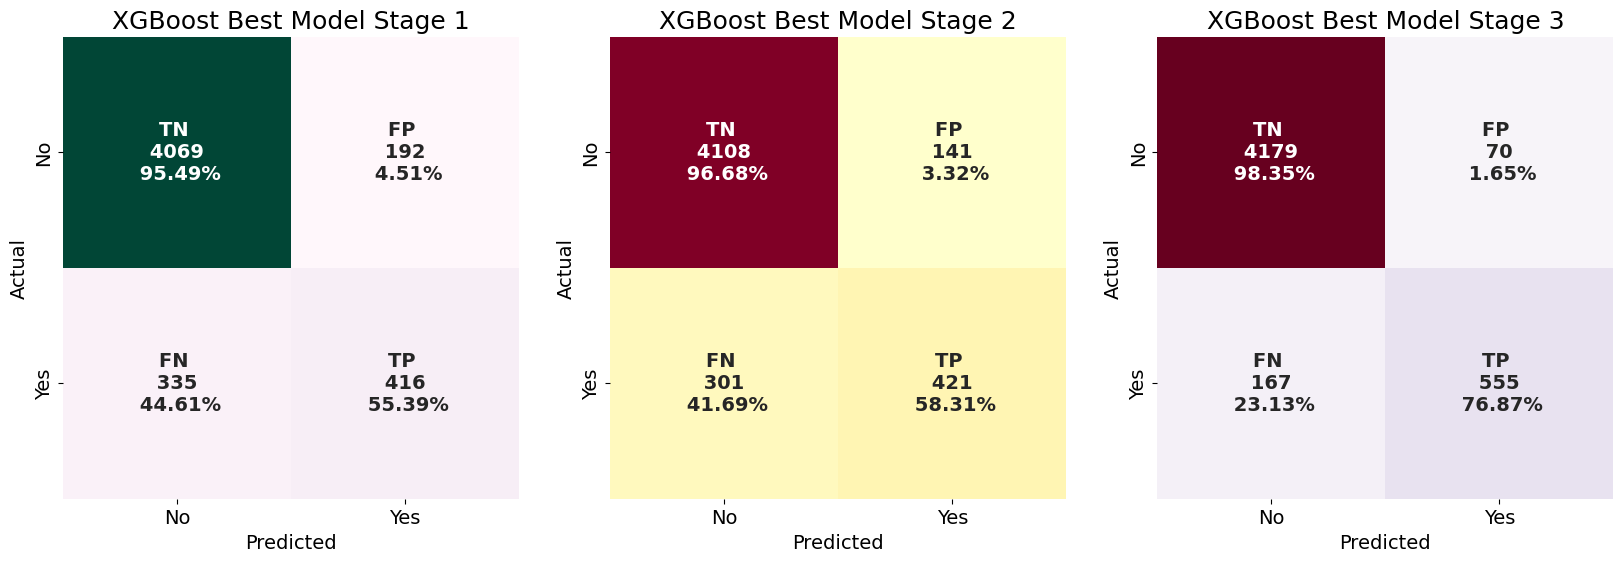

In [ ]:
# Display resulting confusion matrices for all stages

fig, axes = plt.subplots(1, 3, figsize=(20,6))

sns.heatmap(cm_s1_xgb_grid, annot=cm_labels_s1_xgb_grid,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='PuBuGn',ax=axes[0],cbar=False)
sns.heatmap(cm_s2_xgb_base, annot=cm_labels_s2_xgb_base,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='YlOrRd',ax=axes[1],cbar=False)
sns.heatmap(cm_s3_xgb_grid, annot=cm_labels_s3_xgb_grid,annot_kws={"fontsize":14,"fontweight":'bold'},fmt='', cmap='PuRd',ax=axes[2],cbar=False)


for i in range(3):
  axes[i].xaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].yaxis.set_ticklabels(['No', 'Yes'],fontsize=14)
  axes[i].set_xlabel('Predicted',fontsize=14)
  axes[i].set_ylabel('Actual',fontsize=14)

axes[0].set_title('XGBoost Best Model Stage 1',fontsize=18)
axes[1].set_title('XGBoost Best Model Stage 2',fontsize=18)
axes[2].set_title('XGBoost Best Model Stage 3',fontsize=18)



As was the case with the NN models, while the improvement in TPR attained by hyperparameter tuning remains below 5%, the biggest leap occurs with the introduction of new features relating to academic performance in stage 3. This highlights the importance of including features that carry context.

**Future Improvements**

XGBoost:

* As discussed, feature importance scores do not account for the impact of a given feature on the outcome variable. They only inform of which features are contributing more significantly towards the model performance which in this case is determined by the gain metric.

* A better approach would be to use the SHAP values method which accounts for  both the magnitude and the direction of a feature's effect on the model's output, providing information on a local and a global scale.

* Moreover, the SHAP method is argued to be less biased towards the split position/order within the tree, as it operates by averaging possible different orderings.

* For model improvement, further hyperparameters can be included in the process, using hybrid optimisation approaches such as BOHB which is a hybrid between Bayesian Optimisation and Hyperband approaches to cut computational costs.

NN-models:
* As illustrated with the implementation of early stopping in stage 3, further regularisation such as incorporation of dropouts, Ridge or Lasso regularisation or even further hyperparameter tuning can further benefit the model performance.


